## Step 1: Setup and Load Data
In this step we mount Google Drive, load the Give Me Some Credit training file, and take a first look at its shape and columns.

In [4]:
# Step 1: Imports, Google Drive setup, and loading the dataset
import os
import pandas as pd
import numpy as np
from google.colab import drive

# Mount Google Drive so Colab can read the dataset file
drive.mount('/content/drive')

# Path to the training file saved in Google Drive
FILE_PATH = '/content/drive/MyDrive/cs-training.csv.zip'
print('File found:', os.path.exists(FILE_PATH))

# Load the data (the first column is just a row index, so we use it as the index)
df = pd.read_csv(FILE_PATH, index_col=0)

# Basic overview of the dataset
print('Shape (rows, columns):', df.shape)
print()
print(df.dtypes)
df.head()

Mounted at /content/drive
File found: True
Shape (rows, columns): (150000, 11)

SeriousDlqin2yrs                          int64
RevolvingUtilizationOfUnsecuredLines    float64
age                                       int64
NumberOfTime30-59DaysPastDueNotWorse      int64
DebtRatio                               float64
MonthlyIncome                           float64
NumberOfOpenCreditLinesAndLoans           int64
NumberOfTimes90DaysLate                   int64
NumberRealEstateLoansOrLines              int64
NumberOfTime60-89DaysPastDueNotWorse      int64
NumberOfDependents                      float64
dtype: object


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## Step 2: Target Balance and Missing Values
Here we check how many borrowers defaulted (class imbalance) and which columns contain missing values. Both affect how we train the models later.

In [5]:
# Step 2: Check target balance and missing values

# 1) Target distribution: 0 = no serious delinquency, 1 = serious delinquency (90+ days late)
print('Target counts:')
print(df['SeriousDlqin2yrs'].value_counts())
print()
print('Target percentages:')
print((df['SeriousDlqin2yrs'].value_counts(normalize=True) * 100).round(2))
print()

# 2) Missing values per column
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_report = pd.DataFrame({'missing_count': missing, 'missing_percent': missing_pct})
print('Missing values:')
print(missing_report[missing_report['missing_count'] > 0])

# 3) Duplicate rows
print()
print('Duplicate rows:', df.duplicated().sum())

Target counts:
SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64

Target percentages:
SeriousDlqin2yrs
0    93.32
1     6.68
Name: proportion, dtype: float64

Missing values:
                    missing_count  missing_percent
MonthlyIncome               29731            19.82
NumberOfDependents           3924             2.62

Duplicate rows: 609


## Step 3: Summary Statistics and Outlier Check
Before cleaning, we look at the value ranges of each column and check for suspicious values (such as age 0 or extreme ratios).

In [7]:
# Step 3 (clean version): Summary statistics and outlier checks

# 1) Summary statistics for all columns
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
print(df.describe(percentiles=[0.01, 0.99]).T[['min', '1%', '50%', '99%', 'max']])
print()

# 2) Age: values that are not realistic for a borrower
print('Rows with age < 18:', (df['age'] < 18).sum())
print('Age range:', df['age'].min(), 'to', df['age'].max())
print()

# 3) Utilization should normally be between 0 and 1
print('RevolvingUtilization > 1:', (df['RevolvingUtilizationOfUnsecuredLines'] > 1).sum())
print('RevolvingUtilization > 10:', (df['RevolvingUtilizationOfUnsecuredLines'] > 10).sum())
print()

# 4) DebtRatio: very large values
print('DebtRatio > 1:', (df['DebtRatio'] > 1).sum())
print('DebtRatio > 100:', (df['DebtRatio'] > 100).sum())
print()

# 5) Past-due count columns: look at the highest values
for col in ['NumberOfTime30-59DaysPastDueNotWorse',
            'NumberOfTimes90DaysLate',
            'NumberOfTime60-89DaysPastDueNotWorse']:
    print(col, '-> top values:')
    print(df[col].value_counts().sort_index(ascending=False).head(5))
    print()

                                       min     1%       50%        99%  \
SeriousDlqin2yrs                     0.000  0.000     0.000      1.000   
RevolvingUtilizationOfUnsecuredLines 0.000  0.000     0.154      1.093   
age                                  0.000 24.000    52.000     87.000   
NumberOfTime30-59DaysPastDueNotWorse 0.000  0.000     0.000      4.000   
DebtRatio                            0.000  0.000     0.367  4,979.040   
MonthlyIncome                        0.000  0.000 5,400.000 25,000.000   
NumberOfOpenCreditLinesAndLoans      0.000  0.000     8.000     24.000   
NumberOfTimes90DaysLate              0.000  0.000     0.000      3.000   
NumberRealEstateLoansOrLines         0.000  0.000     1.000      4.000   
NumberOfTime60-89DaysPastDueNotWorse 0.000  0.000     0.000      2.000   
NumberOfDependents                   0.000  0.000     0.000      4.000   

                                               max  
SeriousDlqin2yrs                             1.000  
Revol

## Step 4: Basic Cleaning
We remove duplicate rows, impossible ages, and rows with the special codes 96/98 in the past-due columns. We also check whether very large DebtRatio values are linked to missing MonthlyIncome.

In [8]:
# Step 4: Basic cleaning (we keep the original df untouched and work on a copy)
df_clean = df.copy()
print('Start shape:', df_clean.shape)

# 1) Remove duplicate rows
df_clean = df_clean.drop_duplicates()
print('After removing duplicates:', df_clean.shape)

# 2) Remove unrealistic ages (borrowers must be adults)
df_clean = df_clean[df_clean['age'] >= 18]
print('After removing age < 18:', df_clean.shape)

# 3) Special codes 96 and 98 in the past-due columns (not real counts)
past_due_cols = ['NumberOfTime30-59DaysPastDueNotWorse',
                 'NumberOfTimes90DaysLate',
                 'NumberOfTime60-89DaysPastDueNotWorse']
special_code_rows = df_clean[past_due_cols].isin([96, 98]).any(axis=1)

print()
print('Rows with code 96/98:', special_code_rows.sum())
print('Default rate in those rows (%):',
      round(df_clean.loc[special_code_rows, 'SeriousDlqin2yrs'].mean() * 100, 2))
print('Default rate in all other rows (%):',
      round(df_clean.loc[~special_code_rows, 'SeriousDlqin2yrs'].mean() * 100, 2))

df_clean = df_clean[~special_code_rows]
print('After removing special-code rows:', df_clean.shape)

# 4) Check: are very large DebtRatio values linked to missing MonthlyIncome?
high_debt = df_clean['DebtRatio'] > 1
print()
print('Rows with DebtRatio > 1:', high_debt.sum())
print('  of which MonthlyIncome is missing:',
      df_clean.loc[high_debt, 'MonthlyIncome'].isna().sum())
print('Rows with DebtRatio <= 1 and MonthlyIncome missing:',
      df_clean.loc[~high_debt, 'MonthlyIncome'].isna().sum())

# 5) Final overview
print()
print('Final shape:', df_clean.shape)
print('Default rate (%):', round(df_clean['SeriousDlqin2yrs'].mean() * 100, 2))

Start shape: (150000, 11)
After removing duplicates: (149391, 11)
After removing age < 18: (149390, 11)

Rows with code 96/98: 225
Default rate in those rows (%): 60.44
Default rate in all other rows (%): 6.62
After removing special-code rows: (149165, 11)

Rows with DebtRatio > 1: 35103
  of which MonthlyIncome is missing: 27870
Rows with DebtRatio <= 1 and MonthlyIncome missing: 1271

Final shape: (149165, 11)
Default rate (%): 6.62


## Step 5: Exploratory Data Analysis (EDA)

### 5.1 How many borrowers get into serious trouble?
The chart below shows how many borrowers in our data stayed on track, and how many became seriously late (90 or more days overdue) on a payment within two years.

**How to read it:** each bar is a group of borrowers. The taller the bar, the more borrowers in that group.

**What it tells us:** roughly 1 in every 15 borrowers (about 6.6%) ran into serious trouble. This is called a "class imbalance": trouble cases are rare, so a model that simply says "everyone is fine" would be right about 93% of the time but would be useless to a lender. We will therefore judge our models by how well they catch the risky borrowers, not by overall accuracy.

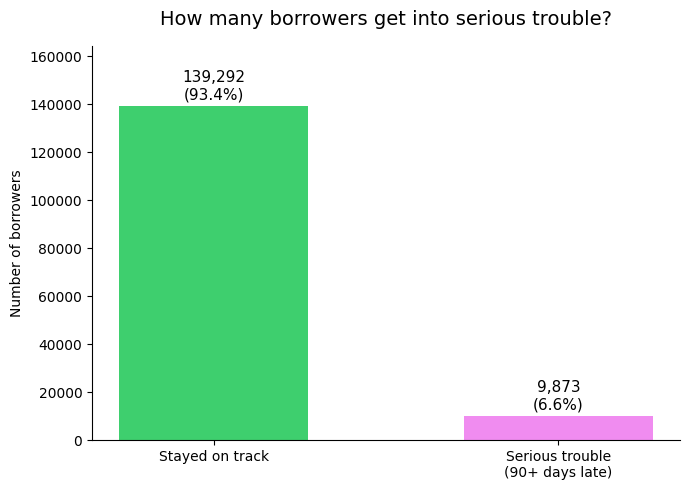

About 1 in 15 borrowers had serious trouble.


In [9]:
# Step 5: EDA - Question 1: how many borrowers get into serious trouble?
import matplotlib.pyplot as plt

# Friendly names for later charts (so non-technical readers see plain English)
friendly_names = {
    'SeriousDlqin2yrs': 'Serious trouble within 2 years',
    'RevolvingUtilizationOfUnsecuredLines': 'Credit card usage (share of limit used)',
    'age': 'Age',
    'NumberOfTime30-59DaysPastDueNotWorse': 'Times 30-59 days late',
    'DebtRatio': 'Debt ratio',
    'MonthlyIncome': 'Monthly income',
    'NumberOfOpenCreditLinesAndLoans': 'Open loans and credit lines',
    'NumberOfTimes90DaysLate': 'Times 90+ days late',
    'NumberRealEstateLoansOrLines': 'Real estate loans',
    'NumberOfTime60-89DaysPastDueNotWorse': 'Times 60-89 days late',
    'NumberOfDependents': 'Number of dependents',
}

# Count borrowers in each group
counts = df_clean['SeriousDlqin2yrs'].value_counts().sort_index()
total = counts.sum()
labels = ['Stayed on track', 'Serious trouble\n(90+ days late)']
colors = ['#3ECF6E', '#F08CF0']

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(labels, counts.values, color=colors, width=0.55)

# Write the count and percentage on top of each bar
for bar, value in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + total * 0.01,
            f'{value:,}\n({value / total:.1%})',
            ha='center', va='bottom', fontsize=11)

ax.set_title('How many borrowers get into serious trouble?', fontsize=14, pad=15)
ax.set_ylabel('Number of borrowers')
ax.set_ylim(0, counts.max() * 1.18)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

print(f'About 1 in {total / counts[1]:.0f} borrowers had serious trouble.')

### 5.2 Who are the borrowers?
The two charts below describe the typical borrower in our data: how old they are and how much they earn per month.

**How to read it:** each bar counts how many borrowers fall into that range (for example, ages 40 to 45). A tall bar means many borrowers are in that range.

**Note on income:** about 1 in 5 borrowers did not report a monthly income, so they are not shown in the income chart. To keep the chart readable, the very highest incomes (top 1%) are left out of the picture, but they stay in the data."

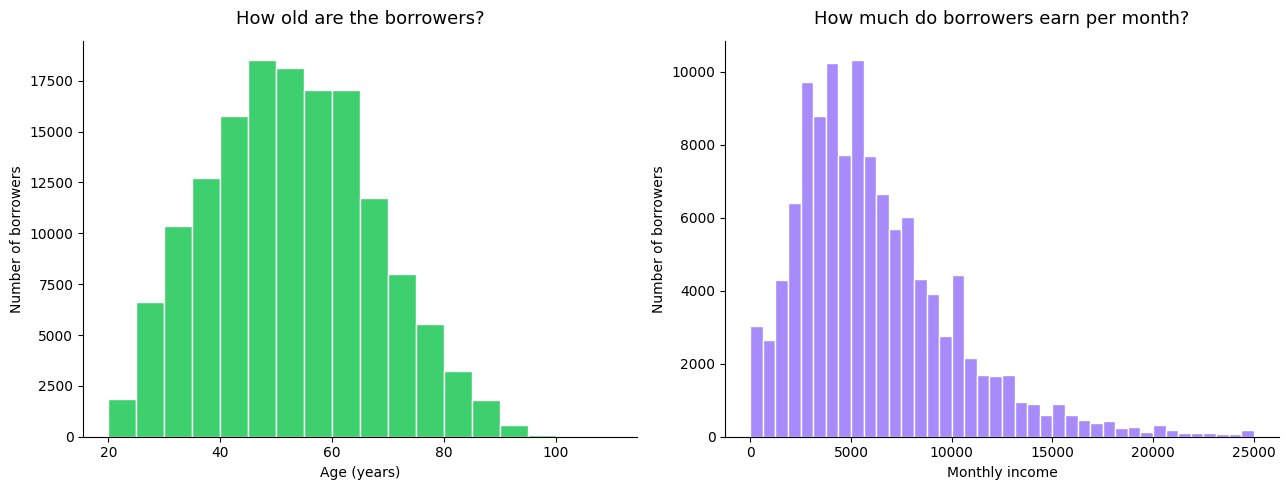

Typical (median) age: 52 years
Youngest / oldest: 21 / 109
Typical (median) monthly income: 5,400
Middle half of incomes: 3,400 to 8,250
Borrowers with no income reported: 19.5%


In [10]:
# Step 5.2: EDA - Question 2: who are the borrowers? (age and income)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Left chart: age distribution ---
axes[0].hist(df_clean['age'], bins=range(20, 111, 5), color='#3ECF6E', edgecolor='white')
axes[0].set_title('How old are the borrowers?', fontsize=13, pad=12)
axes[0].set_xlabel('Age (years)')
axes[0].set_ylabel('Number of borrowers')
axes[0].spines[['top', 'right']].set_visible(False)

# --- Right chart: monthly income distribution (known incomes only) ---
income = df_clean['MonthlyIncome'].dropna()
income_cap = income.quantile(0.99)           # hide the top 1% only for readability
axes[1].hist(income[income <= income_cap], bins=40, color='#A78BFA', edgecolor='white')
axes[1].set_title('How much do borrowers earn per month?', fontsize=13, pad=12)
axes[1].set_xlabel('Monthly income')
axes[1].set_ylabel('Number of borrowers')
axes[1].spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

# Key numbers to quote in the story
print(f"Typical (median) age: {df_clean['age'].median():.0f} years")
print(f"Youngest / oldest: {df_clean['age'].min()} / {df_clean['age'].max()}")
print(f"Typical (median) monthly income: {income.median():,.0f}")
print(f"Middle half of incomes: {income.quantile(0.25):,.0f} to {income.quantile(0.75):,.0f}")
print(f"Borrowers with no income reported: {df_clean['MonthlyIncome'].isna().mean():.1%}")

**What it tells us:** the typical borrower is 52 years old, and the ages in our data run from 21 to 109. The typical borrower earns about 5,400 per month, and the middle half of borrowers earn between 3,400 and 8,250. The currency is not stated in the dataset. About 1 in 5 borrowers (19.5%) did not report any income, which is a gap we will have to handle carefully when we prepare the data for modeling.

### 5.3 Do younger borrowers get into trouble more often?
The chart below splits borrowers into age groups and shows, for each group, what share of borrowers became seriously late (90+ days overdue) within two years.

**How to read it:** each bar is one age group. A taller bar means a larger share of that group got into trouble. The dashed line is the average for all borrowers (about 6.6%), so any bar above the line is riskier than average and any bar below it is safer than average. The small "n" under each label is the number of borrowers in that group.

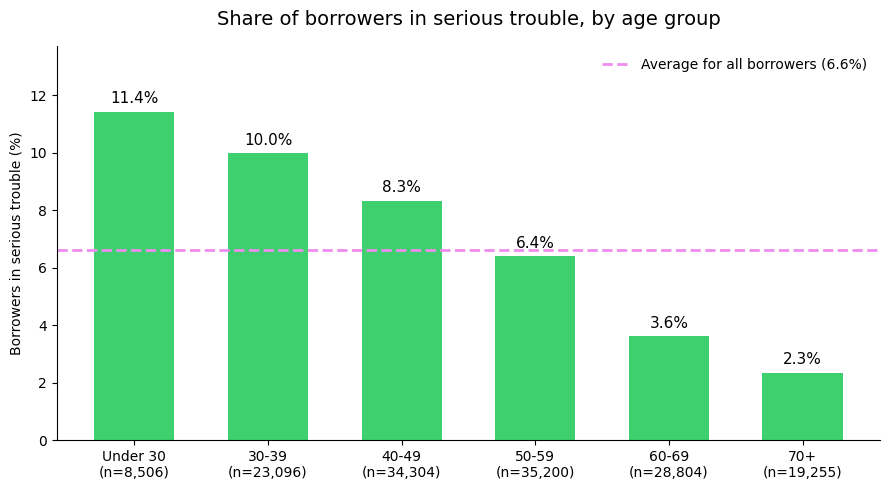

           rate      n
age                   
Under 30 11.440   8506
30-39     9.980  23096
40-49     8.320  34304
50-59     6.400  35200
60-69     3.610  28804
70+       2.330  19255


In [11]:
# Step 5.3: EDA - Question 3: default rate by age group
age_bins = [0, 29, 39, 49, 59, 69, 120]
age_labels = ['Under 30', '30-39', '40-49', '50-59', '60-69', '70+']
age_group = pd.cut(df_clean['age'], bins=age_bins, labels=age_labels)

# Share of borrowers in serious trouble, and group size, for each age group
by_age = (df_clean.groupby(age_group, observed=True)['SeriousDlqin2yrs']
          .agg(rate='mean', n='count'))
overall_rate = df_clean['SeriousDlqin2yrs'].mean()

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(by_age.index.astype(str), by_age['rate'] * 100, color='#3ECF6E', width=0.6)

# Dashed line = average for all borrowers
ax.axhline(overall_rate * 100, color='#F08CF0', linestyle='--', linewidth=2,
           label=f'Average for all borrowers ({overall_rate:.1%})')

# Percentage on top of each bar
for bar, rate in zip(bars, by_age['rate']):
    ax.text(bar.get_x() + bar.get_width() / 2, rate * 100 + 0.2,
            f'{rate:.1%}', ha='center', va='bottom', fontsize=11)

# Group size under each label
ax.set_xticks(range(len(by_age)))
ax.set_xticklabels([f'{g}\n(n={n:,})' for g, n in zip(by_age.index, by_age['n'])])

ax.set_title('Share of borrowers in serious trouble, by age group', fontsize=14, pad=15)
ax.set_ylabel('Borrowers in serious trouble (%)')
ax.set_ylim(0, by_age['rate'].max() * 100 * 1.2)
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

print(by_age.assign(rate=(by_age['rate'] * 100).round(2)))

**What it tells us:** in our data, the younger the borrower, the more often they got into serious trouble. Among borrowers under 30, 11.4% became seriously late, compared with 6.4% for those aged 50 to 59 and just 2.3% for those aged 70 and over. The groups under 50 are above the overall average of 6.6%, and the groups from 50 upwards are at or below it. This shows a pattern in the data, not a cause: age probably stands in for other things, such as how long someone has been earning or how much savings they have built up. Note also that in many places lenders are restricted in how they may use age in real lending decisions, so we treat age here as something to understand, not as a rule to judge people by.

### 5.4 Do borrowers who paid late before get into trouble again?
Each of the three charts below looks at borrowers by how many times they were late on a payment in the past: 30 to 59 days late, 60 to 89 days late, and 90 or more days late.

**How to read it:** the bottom label is the number of past late payments ("4+" means four or more). The height of the bar is the share of those borrowers who then became seriously late (90+ days overdue) within two years. The dashed line is the average for all borrowers (about 6.6%). The small "n" shows how many borrowers are in each bar, so be careful with bars that have very few borrowers.

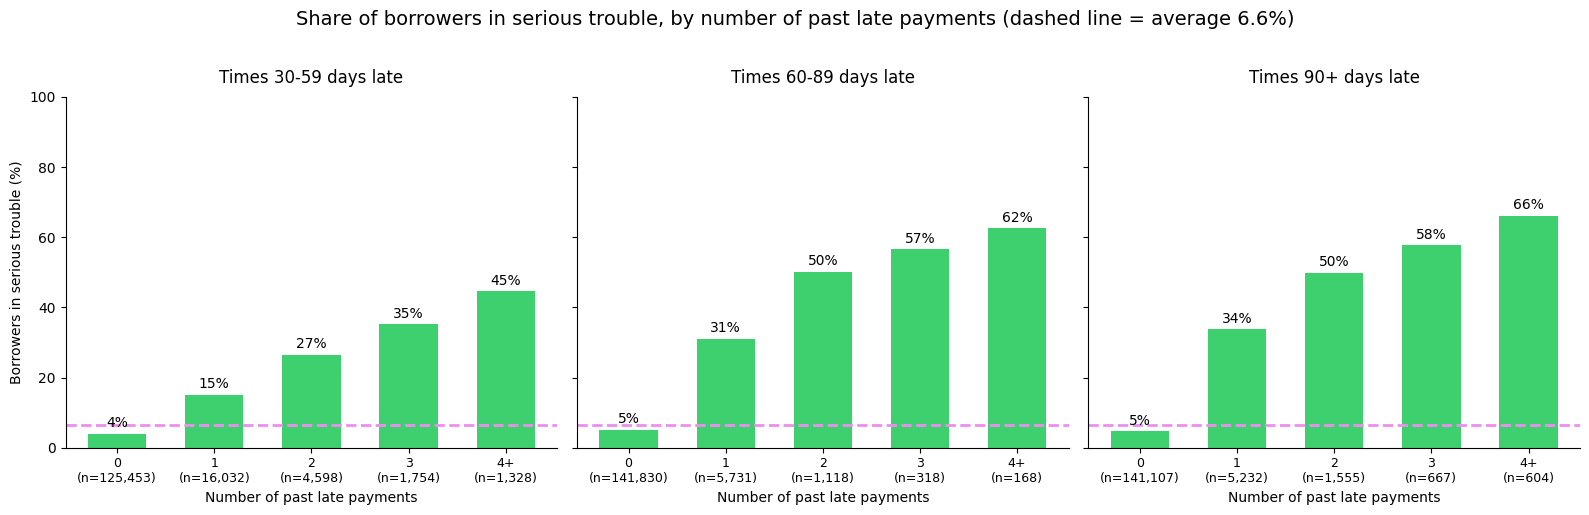

Times 30-59 days late
                                       rate       n
NumberOfTime30-59DaysPastDueNotWorse               
0                                     4.000  125453
1                                    15.000   16032
2                                    26.500    4598
3                                    35.200    1754
4                                    44.600    1328

Times 60-89 days late
                                       rate       n
NumberOfTime60-89DaysPastDueNotWorse               
0                                     5.100  141830
1                                    31.000    5731
2                                    50.200    1118
3                                    56.600     318
4                                    62.500     168

Times 90+ days late
                          rate       n
NumberOfTimes90DaysLate               
0                        4.600  141107
1                       33.700    5232
2                       49.900    1555
3          

In [12]:
# Step 5.4: EDA - Question 4: past late payments vs serious trouble
past_due_cols = {
    'NumberOfTime30-59DaysPastDueNotWorse': 'Times 30-59 days late',
    'NumberOfTime60-89DaysPastDueNotWorse': 'Times 60-89 days late',
    'NumberOfTimes90DaysLate': 'Times 90+ days late',
}
overall_rate = df_clean['SeriousDlqin2yrs'].mean()

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for ax, (col, title) in zip(axes, past_due_cols.items()):
    # Group "4 or more" times together so every bar has enough borrowers
    times_late = df_clean[col].clip(upper=4)
    stats = (df_clean.groupby(times_late)['SeriousDlqin2yrs']
             .agg(rate='mean', n='count'))

    labels = [str(int(i)) if i < 4 else '4+' for i in stats.index]
    bars = ax.bar(labels, stats['rate'] * 100, color='#3ECF6E', width=0.6)

    # Average line for all borrowers
    ax.axhline(overall_rate * 100, color='#F08CF0', linestyle='--', linewidth=2)

    # Percentage on top of each bar and group size under each label
    for bar, rate in zip(bars, stats['rate']):
        ax.text(bar.get_x() + bar.get_width() / 2, rate * 100 + 1,
                f'{rate:.0%}', ha='center', va='bottom', fontsize=10)
    ax.set_xticks(range(len(stats)))
    ax.set_xticklabels([f'{l}\n(n={n:,})' for l, n in zip(labels, stats['n'])], fontsize=9)

    ax.set_title(title, fontsize=12, pad=10)
    ax.set_xlabel('Number of past late payments')
    ax.spines[['top', 'right']].set_visible(False)

axes[0].set_ylabel('Borrowers in serious trouble (%)')
axes[0].set_ylim(0, 100)
fig.suptitle('Share of borrowers in serious trouble, by number of past late payments '
             f'(dashed line = average {overall_rate:.1%})', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Table of the numbers behind the charts
for col, title in past_due_cols.items():
    times_late = df_clean[col].clip(upper=4)
    stats = df_clean.groupby(times_late)['SeriousDlqin2yrs'].agg(rate='mean', n='count')
    stats['rate'] = (stats['rate'] * 100).round(1)
    print(title)
    print(stats)
    print()

**What it tells us:** this is the strongest pattern we have seen so far. Borrowers who were never late before got into serious trouble only about 4% to 5% of the time, which is below the overall average of 6.6%. After just one payment that was 60 or more days late, the share jumps to about one third (31% after one 60-89 day delay, 34% after one 90+ day delay). With three or more such delays, more than half of borrowers got into serious trouble. In other words, a borrower's past behavior is a strong warning sign for their future behavior. One caution: the bars for "4+" late payments rest on fewer borrowers (for example 168 in the 60-89 day chart), so those exact percentages are less reliable than the bars with thousands of borrowers. As always, this shows that the two things go together, not that one causes the other.

### 5.5 Does using more of the credit limit mean more risk?
"Credit usage" is the share of the available credit card and credit line limit that a borrower is currently using. For example, 50% means half of the limit is used, and over 100% means the borrower is above their limit.

**How to read it:** each bar is a group of borrowers with a similar level of usage, from low usage on the left to over the limit on the right. The height of the bar is the share of that group that got into serious trouble (90+ days overdue) within two years. The dashed line is the average for all borrowers (about 6.6%). The small "n" shows how many borrowers are in each group.

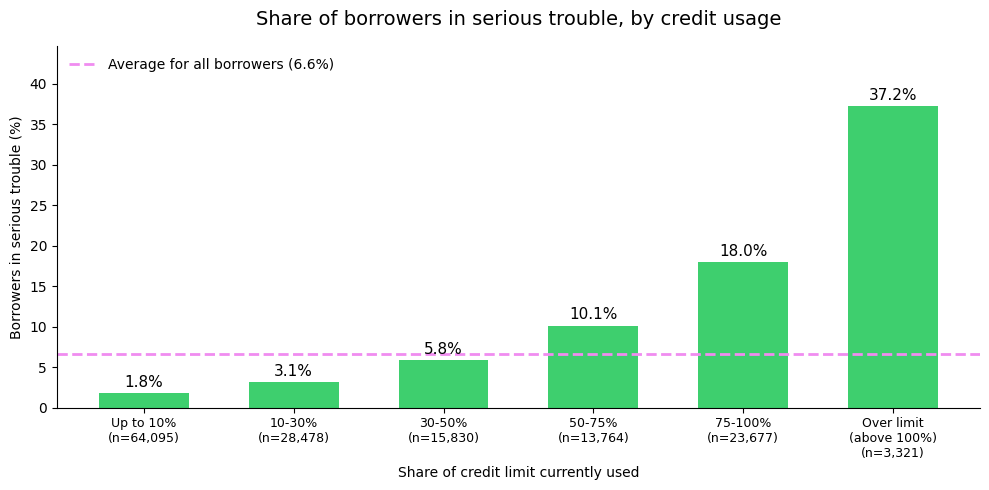

                                       rate      n
RevolvingUtilizationOfUnsecuredLines              
Up to 10%                             1.820  64095
10-30%                                3.140  28478
30-50%                                5.850  15830
50-75%                               10.130  13764
75-100%                              17.970  23677
Over limit\n(above 100%)             37.250   3321

Borrowers using more than 1000% of their limit (likely data errors): 241


In [13]:
# Step 5.5: EDA - Question 5: credit usage vs serious trouble
usage = df_clean['RevolvingUtilizationOfUnsecuredLines']

# Usage bands: share of the credit limit that is used
usage_bins = [-0.001, 0.10, 0.30, 0.50, 0.75, 1.00, np.inf]
usage_labels = ['Up to 10%', '10-30%', '30-50%', '50-75%', '75-100%', 'Over limit\n(above 100%)']
usage_group = pd.cut(usage, bins=usage_bins, labels=usage_labels)

by_usage = (df_clean.groupby(usage_group, observed=True)['SeriousDlqin2yrs']
            .agg(rate='mean', n='count'))
overall_rate = df_clean['SeriousDlqin2yrs'].mean()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(range(len(by_usage)), by_usage['rate'] * 100, color='#3ECF6E', width=0.6)

# Dashed line = average for all borrowers
ax.axhline(overall_rate * 100, color='#F08CF0', linestyle='--', linewidth=2,
           label=f'Average for all borrowers ({overall_rate:.1%})')

# Percentage on top of each bar
for bar, rate in zip(bars, by_usage['rate']):
    ax.text(bar.get_x() + bar.get_width() / 2, rate * 100 + 0.4,
            f'{rate:.1%}', ha='center', va='bottom', fontsize=11)

# Group size under each label
ax.set_xticks(range(len(by_usage)))
ax.set_xticklabels([f'{g}\n(n={n:,})' for g, n in zip(by_usage.index, by_usage['n'])], fontsize=9)

ax.set_title('Share of borrowers in serious trouble, by credit usage', fontsize=14, pad=15)
ax.set_xlabel('Share of credit limit currently used')
ax.set_ylabel('Borrowers in serious trouble (%)')
ax.set_ylim(0, by_usage['rate'].max() * 100 * 1.2)
ax.legend(frameon=False, loc='upper left')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

# Table of the numbers behind the chart
print(by_usage.assign(rate=(by_usage['rate'] * 100).round(2)))
print()
print('Borrowers using more than 1000% of their limit (likely data errors):',
      (usage > 10).sum())

**What it tells us:** the more of their credit limit a borrower uses, the more often they got into serious trouble. About 43% of borrowers (64,095) use less than 10% of their limit, and only 1.8% of them became seriously late. The share rises step by step: 3.1% at 10-30% usage, 5.8% at 30-50%, 10.1% at 50-75%, and 18.0% at 75-100%, which is almost three times the overall average of 6.6%. The highest risk is among borrowers who are above their limit: 37.2% of them got into serious trouble, more than five times the average. This shows a pattern in the data, not a cause: heavy credit use may be a sign that someone is already under financial pressure, rather than the reason for the trouble itself.

### 5.6 Does income matter, and what about borrowers who did not report income?
The chart below groups borrowers by their reported monthly income and shows the share of each group that got into serious trouble (90+ days overdue) within two years. The last bar (purple) is a separate group: borrowers who did not report any income.

**How to read it:** each bar is one income range, from lower income on the left to higher income on the right. The height of the bar is the share of that group that got into trouble. The dashed line is the average for all borrowers (about 6.6%). The small "n" shows how many borrowers are in each group.

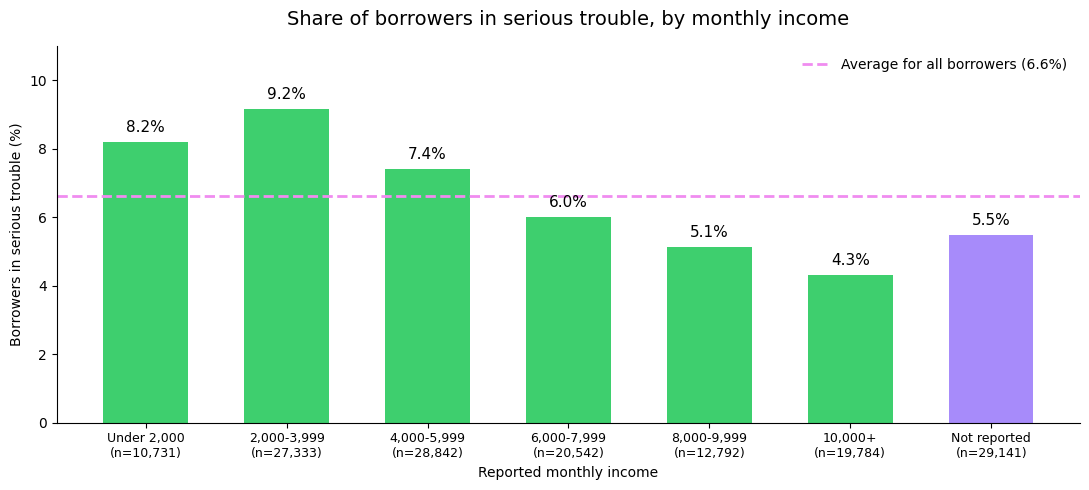

               rate      n
MonthlyIncome             
Under 2,000   8.190  10731
2,000-3,999   9.170  27333
4,000-5,999   7.410  28842
6,000-7,999   6.020  20542
8,000-9,999   5.140  12792
10,000+       4.330  19784
Not reported  5.490  29141


In [14]:
# Step 5.6: EDA - Question 6: income vs serious trouble (including missing income)
income_bins = [0, 2000, 4000, 6000, 8000, 10000, np.inf]
income_labels = ['Under 2,000', '2,000-3,999', '4,000-5,999',
                 '6,000-7,999', '8,000-9,999', '10,000+']

# Put borrowers into income ranges; those with no income get their own group
income_group = pd.cut(df_clean['MonthlyIncome'], bins=income_bins,
                      labels=income_labels, right=False).astype(object)
income_group = income_group.where(df_clean['MonthlyIncome'].notna(), 'Not reported')

order = income_labels + ['Not reported']
by_income = (df_clean.groupby(income_group)['SeriousDlqin2yrs']
             .agg(rate='mean', n='count')
             .reindex(order))
overall_rate = df_clean['SeriousDlqin2yrs'].mean()

# Known income groups in green, "Not reported" in purple
bar_colors = ['#3ECF6E'] * len(income_labels) + ['#A78BFA']

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(range(len(by_income)), by_income['rate'] * 100, color=bar_colors, width=0.6)

# Dashed line = average for all borrowers
ax.axhline(overall_rate * 100, color='#F08CF0', linestyle='--', linewidth=2,
           label=f'Average for all borrowers ({overall_rate:.1%})')

# Percentage on top of each bar
for bar, rate in zip(bars, by_income['rate']):
    ax.text(bar.get_x() + bar.get_width() / 2, rate * 100 + 0.2,
            f'{rate:.1%}', ha='center', va='bottom', fontsize=11)

# Group size under each label
ax.set_xticks(range(len(by_income)))
ax.set_xticklabels([f'{g}\n(n={int(n):,})' for g, n in zip(by_income.index, by_income['n'])],
                   fontsize=9)

ax.set_title('Share of borrowers in serious trouble, by monthly income', fontsize=14, pad=15)
ax.set_xlabel('Reported monthly income')
ax.set_ylabel('Borrowers in serious trouble (%)')
ax.set_ylim(0, by_income['rate'].max() * 100 * 1.2)
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

# Table of the numbers behind the chart
print(by_income.assign(rate=(by_income['rate'] * 100).round(2)))

**What it tells us:** higher income goes with fewer borrowers in serious trouble, but the pattern is not a perfectly straight line. The share is 8.2% for incomes under 2,000, peaks at 9.2% for 2,000-3,999, and then falls steadily to 4.3% for incomes of 10,000 and above, which is about half of the overall average of 6.6%. The most interesting group is the 19.5% of borrowers (29,141) who did not report any income: only 5.5% of them got into serious trouble, which is below average. So a missing income is not a sign of higher risk in this data, and the fact that income is missing may carry information of its own. We will keep track of it with a separate "income not reported" flag when we prepare the data for modeling. As before, this shows a pattern, not a cause.

### 5.7 Which factors move together with serious trouble?
The chart below ranks every factor by how closely it moves together with serious trouble (90+ days overdue within two years). This closeness is called "correlation".

**How to read it:** a bar pointing to the right (pink) means that higher values of that factor go with more trouble. A bar pointing to the left (green) means that higher values go with less trouble. The longer the bar, the stronger the link. A value near 0 means almost no pattern. For example, 0.3 is a clear link, while 0.02 is almost nothing.

**Technical note:** we use the "Spearman" method, which compares rankings instead of raw values, so a few extreme numbers (such as a debt ratio of 300,000) cannot distort the picture.

**Warning:** correlation only shows that two things go together. It does not prove that one causes the other.

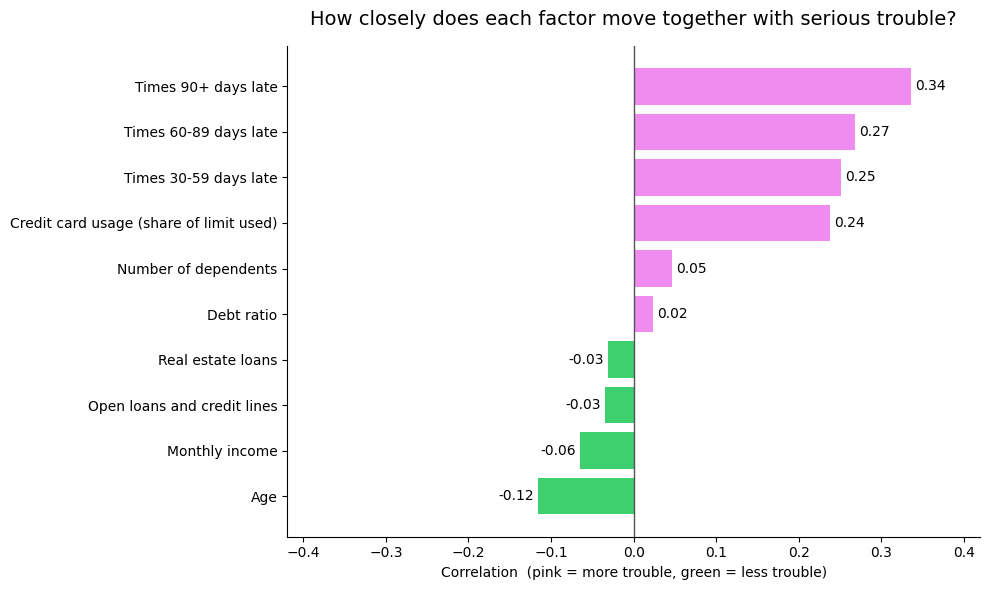

Age                                       -0.115
Monthly income                            -0.065
Open loans and credit lines               -0.034
Real estate loans                         -0.031
Debt ratio                                 0.024
Number of dependents                       0.047
Credit card usage (share of limit used)    0.238
Times 30-59 days late                      0.251
Times 60-89 days late                      0.268
Times 90+ days late                        0.336
Name: SeriousDlqin2yrs, dtype: float64

Strongest overlaps between factors:
                   Factor A                    Factor B  Correlation
Open loans and credit lines           Real estate loans        0.468
                 Debt ratio           Real estate loans        0.394
             Monthly income           Real estate loans        0.389
             Monthly income Open loans and credit lines        0.309
        Times 90+ days late       Times 60-89 days late        0.296


In [15]:
# Step 5.7: EDA - Question 7: which factors move together with serious trouble?
# Spearman correlation compares rankings, so extreme values do not distort it
corr_target = (df_clean.corr(method='spearman')['SeriousDlqin2yrs']
               .drop('SeriousDlqin2yrs')
               .sort_values())

# Use plain-English names (friendly_names was created in Cell 5)
names = [friendly_names[c] for c in corr_target.index]
colors = ['#F08CF0' if v > 0 else '#3ECF6E' for v in corr_target]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(names, corr_target.values, color=colors)

# Write the value at the end of each bar
for bar, value in zip(bars, corr_target.values):
    offset = 0.005 if value >= 0 else -0.005
    ax.text(value + offset, bar.get_y() + bar.get_height() / 2, f'{value:.2f}',
            va='center', ha='left' if value >= 0 else 'right', fontsize=10)

ax.axvline(0, color='#52525B', linewidth=1)
ax.set_title('How closely does each factor move together with serious trouble?',
             fontsize=14, pad=15)
ax.set_xlabel('Correlation  (pink = more trouble, green = less trouble)')
lim = corr_target.abs().max() * 1.25
ax.set_xlim(-lim, lim)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

print(corr_target.round(3).rename(index=friendly_names))

# Which factors overlap with each other? (strongest pairs among the 10 factors)
feat_corr = df_clean.drop(columns='SeriousDlqin2yrs').corr(method='spearman')
upper = np.triu(np.ones(feat_corr.shape), k=1).astype(bool)
pairs = feat_corr.where(upper).stack().reset_index()
pairs.columns = ['Factor A', 'Factor B', 'Correlation']
pairs['Strength'] = pairs['Correlation'].abs()
pairs = pairs.sort_values('Strength', ascending=False).head(5)
pairs['Factor A'] = pairs['Factor A'].map(friendly_names)
pairs['Factor B'] = pairs['Factor B'].map(friendly_names)
print()
print('Strongest overlaps between factors:')
print(pairs[['Factor A', 'Factor B', 'Correlation']].round(3).to_string(index=False))

**What it tells us:** the factors that move most closely with serious trouble are the three kinds of past late payments and credit card usage. The strongest is the number of times a borrower was 90 or more days late (0.34), followed by 60-89 days late (0.27), 30-59 days late (0.25) and credit card usage (0.24). Age goes the other way (-0.12): older borrowers had less trouble, and higher income also leans slightly toward less trouble (-0.06). The remaining factors (number of dependents, debt ratio, real estate loans, open loans and credit lines) have values close to zero, so on their own they show little pattern.

Two things to keep in mind. First, the debt ratio looks weak here (0.02), but earlier we saw that many very large debt ratios belong to borrowers with no reported income, so this number is probably distorted and we should not conclude that debt does not matter. Second, some factors overlap with each other: for example, having many open loans goes together with having real estate loans (0.47).

## 5.8 The story in plain language

We studied about 149,000 borrowers from a public credit dataset (a 2011 Kaggle competition). Each borrower is marked by whether they became seriously late (90 or more days overdue) on a payment within two years. This is what we found:

1. **Serious trouble is rare but real.** About 1 in 15 borrowers (6.6%) got into serious trouble. Because it is rare, we must judge our models by how many risky borrowers they catch, not by overall accuracy.

2. **Past behavior is the strongest warning sign.** Borrowers who were never late before got into trouble only 4% to 5% of the time. After a single payment that was 60 or more days late, about one third did. With three or more such delays, more than half did.

3. **Using up the credit limit is a warning sign.** Among borrowers who used less than 10% of their limit, only 1.8% got into trouble. Among those above their limit, 37.2% did.

4. **Younger borrowers got into trouble more often.** 11.4% of borrowers under 30 did, compared with 2.3% of those aged 70 and over. Age probably stands in for other factors, and in real lending age is often restricted as a decision factor, so we treat it as something to understand, not a rule to judge people by.

5. **Income helps, but less than behavior.** Trouble falls from about 8% to 9% for lower incomes to 4.3% for incomes of 10,000 and above. About 1 in 5 borrowers did not report income, and they were not riskier than average (5.5%), so the missing income is itself a piece of information.

6. **Some numbers needed care.** We removed 609 duplicate rows, one impossible age, and 225 rows with special placeholder codes (96/98) in the late-payment columns. Those 225 rows had a very high trouble rate (60%), so removing them is a choice we document, not a sign they were unimportant.

**Important limits.** These are patterns, not causes. The data comes from one public dataset, not from Pakistani borrowers, and it does not contain tax records or business revenue. Anything our model predicts about a new borrower is only as good as how closely that borrower resembles the people in this dataset.

**Next step:** build and compare models that turn these factors into a probability of serious trouble.

## Step 6: Train/Test Split
Before any preprocessing we split the cleaned data into a training set (80%) and a test set (20%). The test set is locked away and used only once at the end, so our final score reflects how the model performs on borrowers it has never seen. We use a stratified split so both sets keep the same share of serious-trouble cases (about 6.6%).

In [16]:
# Step 6: Train/test split (done BEFORE any preprocessing to avoid data leakage)
from sklearn.model_selection import train_test_split

TARGET = 'SeriousDlqin2yrs'

# Separate the input factors (X) from the answer we want to predict (y)
X = df_clean.drop(columns=TARGET)
y = df_clean[TARGET]

# 80% train / 20% test; stratify keeps the same default rate in both parts
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print('Train shape:', X_train.shape, '| Test shape:', X_test.shape)
print()
print('Serious-trouble rate in train (%):', round(y_train.mean() * 100, 2))
print('Serious-trouble rate in test  (%):', round(y_test.mean() * 100, 2))
print()
print('Serious-trouble cases in train:', y_train.sum(), '| in test:', y_test.sum())
print('Missing MonthlyIncome in train (%):', round(X_train['MonthlyIncome'].isna().mean() * 100, 2))

Train shape: (119332, 10) | Test shape: (29833, 10)

Serious-trouble rate in train (%): 6.62
Serious-trouble rate in test  (%): 6.62

Serious-trouble cases in train: 7898 | in test: 1975
Missing MonthlyIncome in train (%): 19.6


## Step 7: Preprocessing (including Monthly Income normalization)
We build one preprocessing recipe and learn its numbers (medians, means, spreads) from the training set only, so no information from the test set leaks in.

- **Monthly income:** missing values are filled with the training median, a separate "income not reported" flag column is added (missing income carried its own information in the EDA), then we apply a log transform to tame extreme values and a standard scaling (average 0, spread 1).
- **Debt ratio and credit usage:** log transform + standard scaling, because both have extreme values.
- **Late-payment counts, open loans, real estate loans and age:** standard scaling.
- **Number of dependents:** missing values filled with the training median, then standard scaling.

Scaling matters for Logistic Regression; tree-based models (Decision Tree, Random Forest) are not affected by it, but using one recipe for all models keeps the comparison fair.

In [17]:
# Step 7: Preprocessing recipe (fitted on TRAIN only)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import FunctionTransformer, StandardScaler

# Column groups
income_col = ['MonthlyIncome']
ratio_cols = ['DebtRatio', 'RevolvingUtilizationOfUnsecuredLines']
count_cols = ['NumberOfTime30-59DaysPastDueNotWorse',
              'NumberOfTimes90DaysLate',
              'NumberOfTime60-89DaysPastDueNotWorse',
              'NumberOfOpenCreditLinesAndLoans',
              'NumberRealEstateLoansOrLines',
              'age']
dependents_col = ['NumberOfDependents']

# log1p = log(1 + x): safe for zeros and shrinks very large values
log_transform = FunctionTransformer(np.log1p, feature_names_out='one-to-one')

# Income: fill missing -> log -> scale
income_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('log', log_transform),
    ('scale', StandardScaler()),
])

# Ratios: log -> scale
ratio_pipe = Pipeline([
    ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scale', StandardScaler()),
])

# Dependents: fill missing -> scale
dependents_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])

preprocessor = ColumnTransformer([
    ('income', income_pipe, income_col),
    ('income_missing', MissingIndicator(features='all'), income_col),  # 1 = income not reported
    ('ratios', ratio_pipe, ratio_cols),
    ('counts_age', StandardScaler(), count_cols),
    ('dependents', dependents_pipe, dependents_col),
], remainder='drop')
preprocessor.set_output(transform='pandas')

# Learn the numbers from TRAIN only, then apply them to both train and test
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print('Train shape after preprocessing:', X_train_prep.shape)
print('Test shape after preprocessing :', X_test_prep.shape)
print()
print('Columns:')
for c in X_train_prep.columns:
    print('  ', c)

# --- Sanity checks ---
print()
print('Missing values left in train / test:',
      int(X_train_prep.isna().sum().sum()), '/', int(X_test_prep.isna().sum().sum()))

median_used = preprocessor.named_transformers_['income'].named_steps['impute'].statistics_[0]
print('Income median learned from train and used to fill gaps:', median_used)

inc = 'income__MonthlyIncome'
print()
print('Scaled income, TRAIN -> mean:', round(X_train_prep[inc].mean(), 3),
      '| std:', round(X_train_prep[inc].std(), 3))
print('Scaled income, TEST  -> mean:', round(X_test_prep[inc].mean(), 3),
      '| std:', round(X_test_prep[inc].std(), 3))

flag = [c for c in X_train_prep.columns if c.startswith('income_missing')][0]
print()
print('Share of "income not reported" flag, train (%):',
      round(X_train_prep[flag].astype(int).mean() * 100, 2))

Train shape after preprocessing: (119332, 11)
Test shape after preprocessing : (29833, 11)

Columns:
   income__MonthlyIncome
   income_missing__missingindicator_MonthlyIncome
   ratios__DebtRatio
   ratios__RevolvingUtilizationOfUnsecuredLines
   counts_age__NumberOfTime30-59DaysPastDueNotWorse
   counts_age__NumberOfTimes90DaysLate
   counts_age__NumberOfTime60-89DaysPastDueNotWorse
   counts_age__NumberOfOpenCreditLinesAndLoans
   counts_age__NumberRealEstateLoansOrLines
   counts_age__age
   dependents__NumberOfDependents

Missing values left in train / test: 0 / 0
Income median learned from train and used to fill gaps: 5400.0

Scaled income, TRAIN -> mean: -0.0 | std: 1.0
Scaled income, TEST  -> mean: -0.005 | std: 1.015

Share of "income not reported" flag, train (%): 19.6


## Step 8: Compare Three Models with Cross-Validation
We compare Logistic Regression, Decision Tree and Random Forest using 5-fold cross-validation on the training set only. The data is split into 5 parts; each model is trained on 4 parts and scored on the 5th, five times, and we average the results. The test set stays untouched.

All three models use balanced class weights, so mistakes on the rare serious-trouble cases count more during training.

**Metrics (plain language):**
- **PR-AUC (main metric):** how well the model finds the risky borrowers without raising too many false alarms. A model guessing at random would score about 0.066 (the share of risky borrowers), so higher is better and anything well above 0.066 means real signal.
- **ROC-AUC:** how well the model ranks a risky borrower above a safe one. 0.5 is random guessing, 1.0 is perfect.
- **Recall:** of all borrowers who really got into trouble, what share did the model catch.
- **Precision:** of all borrowers the model flagged as risky, what share really got into trouble.
- **F1:** a single score that balances precision and recall.

Recall, precision and F1 use the default cut-off of 50%; we can adjust the cut-off later.

In [18]:
# Step 8: Compare 3 models with 5-fold cross-validation (train set only)
import time
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Candidate models (balanced class weights because only ~6.6% are risky)
models = {
    'Logistic Regression': LogisticRegression(
        class_weight='balanced', max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(
        class_weight='balanced', max_depth=6, min_samples_leaf=50, random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, max_depth=10, min_samples_leaf=20,
        class_weight='balanced_subsample', n_jobs=-1, random_state=42),
}

# Metrics to collect
scoring = {
    'PR-AUC': 'average_precision',
    'ROC-AUC': 'roc_auc',
    'Recall': 'recall',
    'Precision': 'precision',
    'F1': 'f1',
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for name, clf in models.items():
    # Full pipeline: preprocessing is re-learned inside every fold (no leakage)
    pipe = Pipeline([('prep', clone(preprocessor)), ('model', clf)])
    start = time.time()
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    row = {'Model': name}
    for metric in scoring:
        row[metric] = res[f'test_{metric}'].mean()
        row[f'{metric} (std)'] = res[f'test_{metric}'].std()
    row['Time (sec)'] = round(time.time() - start)
    rows.append(row)
    print(f'{name} done in {row["Time (sec)"]} sec')

results = pd.DataFrame(rows).set_index('Model').sort_values('PR-AUC', ascending=False)

print()
print('Mean scores over 5 folds (sorted by PR-AUC):')
print(results[['PR-AUC', 'ROC-AUC', 'Recall', 'Precision', 'F1', 'Time (sec)']].round(3))
print()
print('Spread between folds (std):')
print(results[['PR-AUC (std)', 'ROC-AUC (std)']].round(4))

Logistic Regression done in 5 sec
Decision Tree done in 4 sec
Random Forest done in 136 sec

Mean scores over 5 folds (sorted by PR-AUC):
                     PR-AUC  ROC-AUC  Recall  Precision    F1  Time (sec)
Model                                                                    
Random Forest         0.388    0.864   0.747      0.225 0.346         136
Decision Tree         0.352    0.849   0.753      0.210 0.328           4
Logistic Regression   0.350    0.856   0.727      0.225 0.344           5

Spread between folds (std):
                     PR-AUC (std)  ROC-AUC (std)
Model                                           
Random Forest               0.016          0.004
Decision Tree               0.015          0.005
Logistic Regression         0.009          0.004


**What it tells us:** Random Forest scored best on our main metric (PR-AUC 0.388), ahead of Decision Tree (0.352) and Logistic Regression (0.350). To put this in perspective, a model guessing at random would score about 0.066, so all three models find real signal, and the best one is roughly six times better than guessing. All three catch about three out of four risky borrowers (recall 0.73 to 0.75). The trade-off is that only about 1 in 4 borrowers flagged as risky really got into trouble (precision about 0.22), because we asked the models to take rare cases seriously; this balance can be adjusted later by changing the cut-off.

Random Forest's lead is modest: the folds vary by about 0.015, so the gap over the other two is real but not huge. Decision Tree and Logistic Regression are practically tied. Logistic Regression is much simpler and faster (5 seconds versus 136) and easy to explain, so it remains a useful baseline. We therefore continue with Random Forest and tune it.

## Step 9: Tune the Random Forest
We try 10 different combinations of Random Forest settings ("hyperparameters") using randomized search with 3-fold cross-validation on the training set. The search picks the combination with the best PR-AUC. The test set is still untouched.

**What the settings mean:**
- **n_estimators:** how many trees are in the forest.
- **max_depth:** how deep each tree may grow. Deeper trees fit the training data more closely but can memorize it.
- **min_samples_leaf:** the minimum number of borrowers in a leaf. Larger values make the model simpler and more stable.
- **max_features:** how many factors each tree may look at when making a split.
- **class_weight:** how strongly the rare serious-trouble cases are emphasized.

In [19]:
# Step 9: Hyperparameter tuning for Random Forest (train set only)
from sklearn.model_selection import RandomizedSearchCV

rf_pipe = Pipeline([
    ('prep', clone(preprocessor)),
    ('model', RandomForestClassifier(n_jobs=-1, random_state=42)),
])

# Settings to try (the search samples 10 combinations from these)
param_dist = {
    'model__n_estimators': [150, 250],
    'model__max_depth': [8, 10, 12, 15],
    'model__min_samples_leaf': [5, 10, 20, 40],
    'model__max_features': ['sqrt', 'log2', 0.5],
    'model__class_weight': ['balanced', 'balanced_subsample'],
}

search = RandomizedSearchCV(
    rf_pipe,
    param_distributions=param_dist,
    n_iter=10,
    scoring='average_precision',                 # PR-AUC, our main metric
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True,                                  # refit best settings on the whole train set
)

start = time.time()
search.fit(X_train, y_train)
print(f'Search finished in {round((time.time() - start) / 60, 1)} minutes')

print()
print('Best settings:')
for k, v in search.best_params_.items():
    print(f'  {k.replace("model__", "")}: {v}')
print('Best PR-AUC (3-fold cross-validation):', round(search.best_score_, 3))

# Top 5 combinations
cols = ['mean_test_score', 'std_test_score'] + [c for c in search.cv_results_ if c.startswith('param_')]
top = (pd.DataFrame(search.cv_results_)[cols]
       .sort_values('mean_test_score', ascending=False).head(5))
top.columns = [c.replace('param_model__', '') for c in top.columns]
print()
print('Top 5 combinations:')
print(top.round(3).to_string(index=False))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Search finished in 14.5 minutes

Best settings:
  n_estimators: 250
  min_samples_leaf: 40
  max_features: 0.5
  max_depth: 10
  class_weight: balanced_subsample
Best PR-AUC (3-fold cross-validation): 0.386

Top 5 combinations:
 mean_test_score  std_test_score  n_estimators  min_samples_leaf max_features  max_depth       class_weight
           0.386           0.010           250                40        0.500         10 balanced_subsample
           0.386           0.009           150                20         sqrt         15           balanced
           0.385           0.012           250                40         log2          8           balanced
           0.384           0.009           250                20        0.500         10           balanced
           0.380           0.009           150                10        0.500          8           balanced


**What it tells us:** tuning did not meaningfully improve the Random Forest. The best combination scored a PR-AUC of 0.386, essentially the same as the 0.388 we had before tuning (the two numbers come from slightly different cross-validation setups, so they are close enough to be called equal). The top four combinations are all within 0.002 of each other, which is smaller than the normal variation between folds (about 0.01), so we cannot say any of them is truly better. The practical lesson is that the limit here comes from the information in the ten factors, not from the model settings. We keep the tuned settings because they build smaller, steadier trees (at least 40 borrowers per leaf), which are less likely to memorize the training data.

## Step 10: Check Probabilities and Choose a Cut-off
We use 5-fold cross-validation on the training set to get a prediction for every training borrower from a model that did not see that borrower (these are called out-of-fold predictions). With them we check two things:

1. **Calibration:** when the model says "30% risk", do about 30% of those borrowers really get into trouble? If not, the probability shown on the dashboard would be misleading.
2. **Cut-off (threshold):** the model gives each borrower a risk score between 0 and 1. A cut-off decides who is flagged as "high risk". A low cut-off catches more risky borrowers but raises more false alarms; a high cut-off does the opposite.

The test set is still untouched.

In [20]:
# Step 10: Out-of-fold predictions -> calibration check and cut-off analysis (train set only)
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import average_precision_score, roc_auc_score

# Best Random Forest pipeline from the search (unfitted copy; cross_val_predict refits it per fold)
best_pipe = clone(search.best_estimator_)

start = time.time()
oof_proba = cross_val_predict(best_pipe, X_train, y_train, cv=cv,
                              method='predict_proba', n_jobs=1)[:, 1]
print(f'Out-of-fold predictions done in {round((time.time() - start) / 60, 1)} minutes')

# Overall quality (same 5-fold setup as Step 8, so this is a fair comparison with 0.388)
print()
print('PR-AUC :', round(average_precision_score(y_train, oof_proba), 3))
print('ROC-AUC:', round(roc_auc_score(y_train, oof_proba), 3))

# 1) Calibration: predicted risk vs real share of serious-trouble borrowers
print()
print('Average predicted risk :', round(oof_proba.mean() * 100, 1), '%')
print('Real serious-trouble rate:', round(y_train.mean() * 100, 1), '%')

bins = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0]
band = pd.cut(oof_proba, bins=bins, include_lowest=True)
calib = (pd.DataFrame({'pred': oof_proba, 'real': y_train.values, 'band': band})
         .groupby('band', observed=True)
         .agg(avg_predicted=('pred', 'mean'), real_rate=('real', 'mean'), n=('real', 'size')))
calib[['avg_predicted', 'real_rate']] = (calib[['avg_predicted', 'real_rate']] * 100).round(1)
print()
print('Calibration table (values in %):')
print(calib)

# 2) Cut-off analysis
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    flagged = oof_proba >= t
    tp = int((flagged & (y_train.values == 1)).sum())
    rows.append({
        'cut-off': t,
        'flagged (% of borrowers)': round(flagged.mean() * 100, 1),
        'recall': round(tp / y_train.sum(), 3),
        'precision': round(tp / max(flagged.sum(), 1), 3),
    })
cut_table = pd.DataFrame(rows)
cut_table['F1'] = (2 * cut_table['precision'] * cut_table['recall'] /
                   (cut_table['precision'] + cut_table['recall'])).round(3)
print()
print('Cut-off analysis:')
print(cut_table.to_string(index=False))

Out-of-fold predictions done in 4.2 minutes

PR-AUC : 0.388
ROC-AUC: 0.864

Average predicted risk : 30.6 %
Real serious-trouble rate: 6.6 %

Calibration table (values in %):
               avg_predicted  real_rate      n
band                                          
(-0.001, 0.1]          6.900      0.500  25667
(0.1, 0.2]            14.500      1.300  31888
(0.2, 0.3]            24.500      2.700  15953
(0.3, 0.4]            34.800      4.200  10188
(0.4, 0.5]            44.900      6.000   9042
(0.5, 0.6]            55.000      9.600   9335
(0.6, 0.7]            64.400     14.000   5213
(0.7, 0.8]            75.100     22.500   4195
(0.8, 1.0]            88.500     43.100   7851

Cut-off analysis:
 cut-off  flagged (% of borrowers)  recall  precision    F1
   0.300                    38.400   0.877      0.151 0.258
   0.400                    29.900   0.823      0.182 0.298
   0.500                    22.300   0.754      0.224 0.345
   0.600                    14.500   0.640      0

**What it tells us:** the model ranks borrowers well: the higher the predicted risk band, the more borrowers in that band really got into trouble, from 0.5% in the lowest band to 43.1% in the highest. However, the risk numbers themselves are far too high. On average the model predicts 30.6% risk while only 6.6% of borrowers really got into trouble, and when the model says 88.5%, only about 43% of those borrowers did. This is expected: we told the model to take the rare risky cases extra seriously (balanced class weights), which pushes its scores up. So these raw scores are good for ranking borrowers but must not be shown as real probabilities. We fix this in the next step.

For the cut-off, a cut-off of 0.5 flags 22.3% of borrowers and catches 75.4% of the risky ones (precision 22.4%). A cut-off of 0.7 flags only 10.1% of borrowers and catches 54.7% of the risky ones, with 35.9% of the flagged borrowers really getting into trouble. The best balance (F1) is around 0.7 to 0.8. These cut-offs apply to the inflated scores, so we will set the final cut-offs after calibration.

## Step 11: Calibrate the Probabilities
We learn a small "translator" that converts the model's raw risk scores into real probabilities, using the out-of-fold scores from Step 10. We compare two methods:

- **Isotonic calibration:** flexible, maps scores to real rates step by step.
- **Sigmoid (Platt) calibration:** fits one smooth S-shaped curve.

**Metric (plain language):** the **Brier score** measures how far the predicted probabilities are from what really happened (1 for trouble, 0 for no trouble). Lower is better. As a reference, a lazy model that always says "6.6%" gets a Brier score of about 0.062.

Each method is itself checked with cross-validation, so the comparison is honest. The test set is still untouched.

In [22]:
# Step 11: Compare calibration methods on out-of-fold scores (train set only)
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss

scores = oof_proba
y_arr = y_train.values

def to_logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

# Cross-validated calibration: learn the translator on 4 parts, apply it on the 5th
skf_cal = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
iso_pred = np.zeros(len(scores))
sig_pred = np.zeros(len(scores))

for tr, va in skf_cal.split(scores, y_arr):
    iso = IsotonicRegression(y_min=0, y_max=1, out_of_bounds='clip').fit(scores[tr], y_arr[tr])
    iso_pred[va] = iso.predict(scores[va])

    sig = LogisticRegression().fit(to_logit(scores[tr]), y_arr[tr])
    sig_pred[va] = sig.predict_proba(to_logit(scores[va]))[:, 1]

# Compare: raw scores vs the two calibration methods
base_rate = y_arr.mean()
summary = pd.DataFrame({
    'Average predicted risk (%)': [scores.mean() * 100, iso_pred.mean() * 100, sig_pred.mean() * 100],
    'Brier score (lower = better)': [brier_score_loss(y_arr, scores),
                                     brier_score_loss(y_arr, iso_pred),
                                     brier_score_loss(y_arr, sig_pred)],
    'PR-AUC': [average_precision_score(y_arr, scores),
               average_precision_score(y_arr, iso_pred),
               average_precision_score(y_arr, sig_pred)],
}, index=['Raw scores', 'Isotonic', 'Sigmoid']).round(3)

print('Real serious-trouble rate (%):', round(base_rate * 100, 2))
print('Brier score of a lazy model that always says the average:',
      round(base_rate * (1 - base_rate), 4))
print()
print(summary)

# Calibration tables: predicted risk vs real rate, after calibration
bins = [0, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30, 0.50, 1.0]
for name, pred in [('Isotonic', iso_pred), ('Sigmoid', sig_pred)]:
    band = pd.cut(pred, bins=bins, include_lowest=True)
    tab = (pd.DataFrame({'pred': pred, 'real': y_arr, 'band': band})
           .groupby('band', observed=True)
           .agg(avg_predicted=('pred', 'mean'), real_rate=('real', 'mean'), n=('real', 'size')))
    tab[['avg_predicted', 'real_rate']] = (tab[['avg_predicted', 'real_rate']] * 100).round(1)
    print()
    print(f'{name} calibration table (values in %):')
    print(tab)

Real serious-trouble rate (%): 6.62
Brier score of a lazy model that always says the average: 0.0618

            Average predicted risk (%)  Brier score (lower = better)  PR-AUC
Raw scores                      30.599                         0.132   0.388
Isotonic                         6.618                         0.049   0.382
Sigmoid                          6.623                         0.049   0.388

Isotonic calibration table (values in %):
                avg_predicted  real_rate      n
band                                           
(-0.001, 0.02]          0.900      0.900  55947
(0.02, 0.05]            3.100      3.200  26583
(0.05, 0.1]             7.200      7.100  16499
(0.1, 0.15]            11.800     11.700   6924
(0.15, 0.2]            18.500     19.500   1925
(0.2, 0.3]             23.900     23.500   4328
(0.3, 0.5]             38.100     38.200   5034
(0.5, 1.0]             60.300     59.500   2092

Sigmoid calibration table (values in %):
                avg_predi

**What it tells us:** both calibration methods fixed the problem. The average predicted risk dropped from 30.6% to about 6.6%, matching the real rate, and the Brier score fell from 0.132 to 0.049 (the raw scores were even worse than the lazy 0.062 baseline, both calibrated versions beat it). In the calibration tables, the predicted risk of each band now matches the real share of borrowers who got into trouble: for example, borrowers with a predicted risk of about 38% really got into trouble 38% of the time. We choose sigmoid calibration because it is just as accurate as isotonic here, keeps the ranking of borrowers unchanged (PR-AUC 0.388, versus 0.382 for isotonic, which merges some scores), and is a smooth curve that is easy to explain. These checks used cross-validation on the training set, so the real proof will be the test set.

## Step 12: Choose Cut-offs and Risk Bands (on calibrated probabilities)
The probabilities are now realistic, so a cut-off such as "15%" means "flag borrowers whose predicted chance of serious trouble is 15% or more". Using the cross-validated calibrated probabilities from Step 11 (training data only), we look at what each cut-off would do, and we draft three risk bands for the dashboard.

**How to read the cut-off table:**
- **flagged:** the share of all borrowers who would be marked as risky.
- **recall:** of all borrowers who really got into trouble, the share we caught.
- **precision:** of the borrowers we flagged, the share who really got into trouble.

**How to read the risk-band table:** it shows, for each draft band, how many borrowers fall into it and how many of them really got into trouble. A good set of bands should show a clear step up from Low to High.

In [24]:
# Step 12: Cut-offs and risk bands on calibrated probabilities (train set only, no test data)
cal_proba = sig_pred            # cross-validated sigmoid-calibrated probabilities from Step 11
y_arr = y_train.values
total_risky = y_arr.sum()

# 1) Cut-off analysis
rows = []
for t in [0.05, 0.08, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50]:
    flagged = cal_proba >= t
    tp = int((flagged & (y_arr == 1)).sum())
    rows.append({
        'cut-off': f'{t:.0%}',
        'flagged (% of borrowers)': round(flagged.mean() * 100, 1),
        'recall': round(tp / total_risky, 3),
        'precision': round(tp / max(flagged.sum(), 1), 3),
    })
cut_table = pd.DataFrame(rows)
cut_table['F1'] = (2 * cut_table['precision'] * cut_table['recall'] /
                   (cut_table['precision'] + cut_table['recall'])).round(3)
print('Cut-off analysis:')
print(cut_table.to_string(index=False))

# 2) Draft risk bands for the dashboard (can be changed later)
band_edges = [0, 0.05, 0.15, 0.30, 1.0]
band_names = ['Low (under 5%)', 'Medium (5-15%)', 'High (15-30%)', 'Very high (30%+)']
band = pd.cut(cal_proba, bins=band_edges, labels=band_names, include_lowest=True)

df_band = pd.DataFrame({'band': band, 'real': y_arr, 'pred': cal_proba})
band_table = (df_band.groupby('band', observed=True)
              .agg(borrowers=('real', 'size'),
                   avg_predicted=('pred', 'mean'),
                   real_rate=('real', 'mean'),
                   risky_count=('real', 'sum')))

band_table['share_of_borrowers_%'] = (band_table['borrowers'] / len(y_arr) * 100).round(1)
band_table['share_of_all_risky_%'] = (band_table['risky_count'] / total_risky * 100).round(1)
band_table[['avg_predicted', 'real_rate']] = (band_table[['avg_predicted', 'real_rate']] * 100).round(1)
band_table = band_table.drop(columns='risky_count')

print()
print('Draft risk bands (avg_predicted and real_rate in %):')
print(band_table)


Cut-off analysis:
cut-off  flagged (% of borrowers)  recall  precision    F1
     5%                    30.700   0.830      0.179 0.294
     8%                    21.700   0.745      0.227 0.348
    10%                    17.100   0.683      0.264 0.381
    15%                    11.100   0.575      0.344 0.430
    20%                     8.700   0.506      0.383 0.436
    30%                     5.700   0.388      0.453 0.418
    40%                     3.500   0.277      0.522 0.362
    50%                     2.000   0.174      0.588 0.269

Draft risk bands (avg_predicted and real_rate in %):
                  borrowers  avg_predicted  real_rate  share_of_borrowers_%  \
band                                                                          
Low (under 5%)        82667          1.600      1.600                69.300   
Medium (5-15%)        23451          8.700      8.600                19.700   
High (15-30%)          6453         21.400     22.900                 5.400   
Ve

What it tells us

We tested different "alarm levels" for flagging risky borrowers. A low alarm level (5%) catches 83% of the people who later default, but flags almost a third of all borrowers, and only about 1 in 6 of those flagged actually defaults. A high alarm level (50%) is much more accurate when it flags someone (about 6 in 10 default), but it catches only 17% of defaulters. The best balance between the two is around 15% to 20%: flagging roughly 9-11% of borrowers catches about half to 57% of all defaulters.

Grouping borrowers into four risk bands works well. The Low band (69% of borrowers) has a real default rate of just 1.6%. The Medium band is 8.6%, High is 22.9%, and Very high is 45.3%. In every band, the predicted risk is close to the real default rate, so the percentages we show users can be trusted at face value. The Very high band is only 5.7% of borrowers but holds 38.8% of all defaulters.

Limits: The model is not perfect. About 17% of defaulters still land in the Low band, so a Low result means "much safer than average", not "guaranteed safe". The High band is slightly under-predicted (21.4% predicted vs 22.9% real).

Step 20: Build the final scoring system (test set NOT used here)

In this step we assemble the complete system that will run inside the dashboard:

Fit the tuned Random Forest pipeline on the full training data.
Fit the sigmoid (Platt) calibrator on the out-of-fold scores, so raw scores become real probabilities.
Wrap everything into one function: borrower data in, then probability and risk band out.
Fix the decision rules: risk bands at 5% / 15% / 30%, and a "flag for review" cut-off at 15%.

We only run sanity checks on training data. The test set stays untouched until the next step.

In [26]:
# Cell 20: final model, calibrator, scoring function (no test data used)
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

# 1) Decision rules (fixed here, before we ever look at the test set)
BAND_EDGES = [0.0, 0.05, 0.15, 0.30, 1.0]
BAND_LABELS = ["Low (under 5%)", "Medium (5-15%)", "High (15-30%)", "Very high (30%+)"]
FLAG_CUTOFF = 0.15

# 2) Fit the tuned pipeline (preprocessing + Random Forest) on the full training set
final_pipe = clone(search.best_estimator_)
final_pipe.fit(X_train, y_train)

# 3) Helper: convert probabilities to log-odds (clipped to avoid infinity)
def logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

# 4) Fit the sigmoid calibrator on out-of-fold raw scores (honest scores, not in-sample)
calibrator = LogisticRegression(C=1e6, max_iter=1000)
calibrator.fit(logit(oof_proba), y_train)

# 5) Full scoring function: raw data -> raw score -> probability -> band -> flag
def score_borrowers(X):
    raw = final_pipe.predict_proba(X)[:, 1]
    prob = calibrator.predict_proba(logit(raw))[:, 1]
    band = pd.cut(prob, bins=BAND_EDGES, labels=BAND_LABELS,
                  include_lowest=True, right=False)
    return pd.DataFrame({
        "raw_score": raw,
        "default_probability": prob,
        "risk_band": band,
        "flag_for_review": prob >= FLAG_CUTOFF,
    }, index=X.index)

# 6) Sanity check A: calibrator on out-of-fold scores (should be close to Cell 18/19)
oof_cal = calibrator.predict_proba(logit(oof_proba))[:, 1]
print("Calibrator slope and intercept:", calibrator.coef_[0][0].round(3), calibrator.intercept_[0].round(3))
print("Average calibrated probability (train OOF): %.2f%%  | real rate: %.2f%%"
      % (oof_cal.mean() * 100, y_train.mean() * 100))

oof_bands = pd.cut(oof_cal, bins=BAND_EDGES, labels=BAND_LABELS, include_lowest=True, right=False)
check = (pd.DataFrame({"band": oof_bands, "y": y_train.values})
         .groupby("band", observed=True)["y"]
         .agg(borrowers="count", real_rate_pct=lambda s: round(s.mean() * 100, 1)))
print("\nBand check on training out-of-fold scores:")
print(check)

# 7) Sanity check B: the function works end to end on 3 training rows
print("\nExample output of score_borrowers (3 training rows):")
print(score_borrowers(X_train.head(3)).round(3))

Calibrator slope and intercept: 1.039 -2.475
Average calibrated probability (train OOF): 6.62%  | real rate: 6.62%

Band check on training out-of-fold scores:
                  borrowers  real_rate_pct
band                                      
Low (under 5%)        82671          1.600
Medium (5-15%)        23447          8.600
High (15-30%)          6464         22.900
Very high (30%+)       6750         45.300

Example output of score_borrowers (3 training rows):
       raw_score  default_probability       risk_band  flag_for_review
43435      0.088                0.007  Low (under 5%)            False
67832      0.236                0.024  Low (under 5%)            False
72509      0.388                0.050  Low (under 5%)            False


What it tells us

The final scoring system is assembled and works from start to finish: borrower data goes in, and a default probability, a risk band and a review flag come out.

On the training data, the average predicted risk is 6.62%, exactly the real default rate of 6.62%. The four risk bands also line up with reality: 1.6% of borrowers default in the Low band, 8.6% in Medium, 22.9% in High and 45.3% in Very high. These numbers match the earlier analysis, so the pieces were joined correctly.

The calibrator's slope is about 1.04, which means it mostly shifts the raw scores down to realistic levels and does not distort their ordering. In the three example rows, a raw score of 0.088 becomes a 0.7% probability, and 0.388 becomes about 5.0%. This shows why raw scores must never be shown to users directly.

Limit: These checks use training data (out-of-fold scores), so they confirm the build is correct but are not proof of real-world accuracy. The test set in the next step is the real exam. The third example is just under the 5% line (it displays as 0.050 after rounding), so it sits in the Low band

Step 21: Final exam on the untouched test set

This is the first and only time we use the test set (29,833 borrowers the model has never seen). We measure:

Ranking quality: PR-AUC and ROC-AUC, with a 95% uncertainty range from resampling.
Probability quality: Brier score against a "lazy" baseline that gives everyone the average risk, plus average predicted vs real default rate.
Decision quality at the 15% review cut-off: how many borrowers are flagged, recall and precision.
Calibration: do the predicted percentages match real default rates in each risk band?

We report the results honestly, even if they are worse than in cross-validation. No changes to the model or thresholds will be made after this step.

In [27]:
# Cell 21: one-time evaluation on the untouched test set
import numpy as np
import pandas as pd
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             brier_score_loss, precision_score,
                             recall_score, f1_score)

# 1) Score the test set with the full system (model -> calibrator -> band -> flag)
test_out = score_borrowers(X_test)
p_test = test_out["default_probability"].values
y_t = y_test.values

# 2) Ranking quality
pr_auc = average_precision_score(y_t, p_test)
roc_auc = roc_auc_score(y_t, p_test)

# 3) Uncertainty range: bootstrap the test set (200 resamples)
rng = np.random.RandomState(42)
boot_pr, boot_roc = [], []
for _ in range(200):
    idx = rng.randint(0, len(y_t), len(y_t))
    if y_t[idx].sum() == 0:
        continue
    boot_pr.append(average_precision_score(y_t[idx], p_test[idx]))
    boot_roc.append(roc_auc_score(y_t[idx], p_test[idx]))
pr_lo, pr_hi = np.percentile(boot_pr, [2.5, 97.5])
roc_lo, roc_hi = np.percentile(boot_roc, [2.5, 97.5])

# 4) Probability quality (lazy baseline = everyone gets the training default rate)
brier = brier_score_loss(y_t, p_test)
lazy = brier_score_loss(y_t, np.full(len(y_t), y_train.mean()))

print("=== Ranking quality (test set) ===")
print(f"PR-AUC : {pr_auc:.3f}  (95% range {pr_lo:.3f} to {pr_hi:.3f})  | random guessing about {y_t.mean():.3f}")
print(f"ROC-AUC: {roc_auc:.3f}  (95% range {roc_lo:.3f} to {roc_hi:.3f})")

print("\n=== Probability quality (test set) ===")
print(f"Average predicted risk: {p_test.mean()*100:.2f}%  | real default rate: {y_t.mean()*100:.2f}%")
print(f"Brier score: {brier:.4f}  | lazy baseline: {lazy:.4f}")

# 5) Decision quality at the review cut-off
flag = test_out["flag_for_review"].values
print(f"\n=== Decision at {FLAG_CUTOFF*100:.0f}% cut-off (test set) ===")
print(f"Flagged borrowers: {flag.mean()*100:.1f}% of all")
print(f"Recall   : {recall_score(y_t, flag):.3f}")
print(f"Precision: {precision_score(y_t, flag):.3f}")
print(f"F1       : {f1_score(y_t, flag):.3f}")

# 6) Calibration by risk band
band_table = (pd.DataFrame({"band": test_out["risk_band"].values,
                            "pred": p_test, "y": y_t})
              .groupby("band", observed=True)
              .agg(borrowers=("y", "count"),
                   avg_predicted_pct=("pred", lambda s: round(s.mean() * 100, 1)),
                   real_rate_pct=("y", lambda s: round(s.mean() * 100, 1)),
                   defaulters=("y", "sum")))
band_table["share_of_borrowers_pct"] = (band_table["borrowers"] / len(y_t) * 100).round(1)
band_table["share_of_all_risky_pct"] = (band_table["defaulters"] / y_t.sum() * 100).round(1)
print("\n=== Calibration by risk band (test set) ===")
print(band_table.drop(columns="defaulters"))

=== Ranking quality (test set) ===
PR-AUC : 0.386  (95% range 0.363 to 0.409)  | random guessing about 0.066
ROC-AUC: 0.855  (95% range 0.847 to 0.865)

=== Probability quality (test set) ===
Average predicted risk: 6.68%  | real default rate: 6.62%
Brier score: 0.0495  | lazy baseline: 0.0618

=== Decision at 15% cut-off (test set) ===
Flagged borrowers: 11.3% of all
Recall   : 0.561
Precision: 0.329
F1       : 0.415

=== Calibration by risk band (test set) ===
                  borrowers  avg_predicted_pct  real_rate_pct  \
band                                                            
Low (under 5%)        20596              1.700          1.700   
Medium (5-15%)         5869              8.700          8.800   
High (15-30%)          1693             21.400         21.400   
Very high (30%+)       1675             46.400         44.500   

                  share_of_borrowers_pct  share_of_all_risky_pct  
band                                                              
Low (und

What it tells us

This is the final exam on 29,833 borrowers the model had never seen, and the results held up almost exactly as in our earlier cross-validation tests.

Ranking: The model's ability to put riskier borrowers above safer ones is good but not perfect. The ROC-AUC is 0.855 (cross-validation: 0.864), meaning that if we pick one borrower who defaulted and one who did not, the model ranks the defaulter as riskier about 85% of the time. The PR-AUC is 0.386 (cross-validation: 0.388), about six times better than random guessing (0.066). The uncertainty ranges are fairly narrow (ROC-AUC 0.847 to 0.865), so these results are stable, not a lucky draw.

Probabilities: The average predicted risk is 6.68% against a real default rate of 6.62%, so the percentages are realistic. The Brier score (0.0495) beats the "lazy" baseline of giving everyone the average (0.0618).

Decisions: With the 15% review cut-off, 11.3% of borrowers are flagged. This catches 56% of all people who later default. About 1 in 3 flagged borrowers (33%) actually defaults, so roughly two thirds of flags are false alarms.

Risk bands: Predicted and real default rates match well in Low (1.7% vs 1.7%), Medium (8.7% vs 8.8%) and High (21.4% vs 21.4%). The Very high band is slightly over-predicted (46.4% predicted vs 44.5% real), a small gap. The Very high band is only 5.6% of borrowers but holds 37.7% of all defaulters, while the Low band (69% of borrowers) still contains 17.6% of defaulters.

Limits: The model is useful for ranking and for rough risk levels, not for deciding on its own who gets a loan. The data is from a 2011 consumer credit dataset, not from Pakistani borrowers

Step 21b: Confusion matrix on the test set (reporting only)

We show how many borrowers fall into each outcome at the fixed 15% review cut-off, plus accuracy. This is only a report: the model and the cut-off are not changed after seeing it. Accuracy alone is misleading here, because a model that calls everyone "safe" would already be right about 93% of the time, so we compare against that baseline

In [28]:
# Cell 21b: confusion matrix and accuracy on the test set (no changes to the model)
from sklearn.metrics import confusion_matrix, accuracy_score

flag = test_out["flag_for_review"].values
y_t = y_test.values

tn, fp, fn, tp = confusion_matrix(y_t, flag).ravel()

cm = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Real: repaid", "Real: defaulted"],
    columns=["Predicted: safe", "Predicted: flagged"],
)
print(f"Confusion matrix at {FLAG_CUTOFF*100:.0f}% cut-off (test set):")
print(cm)

print(f"\nAccuracy: {accuracy_score(y_t, flag):.4f}")
print(f"Baseline accuracy (call everyone safe): {1 - y_t.mean():.4f}")
print(f"Specificity (repaid borrowers correctly left alone): {tn / (tn + fp):.3f}")
print(f"Recall (defaulters caught): {tp / (tp + fn):.3f}")
print(f"Precision (flagged who really default): {tp / (tp + fp):.3f}")

Confusion matrix at 15% cut-off (test set):
                 Predicted: safe  Predicted: flagged
Real: repaid               25598                2260
Real: defaulted              867                1108

Accuracy: 0.8952
Baseline accuracy (call everyone safe): 0.9338
Specificity (repaid borrowers correctly left alone): 0.919
Recall (defaulters caught): 0.561
Precision (flagged who really default): 0.329


What it tells us

At the 15% review cut-off, the model is right about 89.5% of the time overall. That number sounds high, but it is actually lower than the 93.4% we would get by simply calling every borrower "safe". So accuracy is not the right way to judge this model. The model is built to find risky borrowers, not to maximise the overall hit rate.

Here is what really happens to the 29,833 test borrowers:

1,108 defaulters were caught (flagged and really defaulted). This is 56% of all 1,975 defaulters.
867 defaulters were missed (not flagged but defaulted). These are the model's most costly mistakes.
2,260 good borrowers were flagged by mistake (false alarms). This is about 8% of all repaying borrowers, so 92% of good borrowers were correctly left alone.
25,598 good borrowers were correctly left alone

Step 22: Explaining the model with SHAP (training sample only)

A probability alone is not enough for a lender; they also want to know why. SHAP splits each prediction into contributions, showing how much each input pushed the risk up or down compared with an average borrower.

In this step we:

Take a random sample of 2,000 training borrowers (the test set is not used).
Measure which inputs matter most on average across all of them.
Look at one high-risk borrower to see which inputs drove their score.

Important: SHAP explains the model's raw score, not the final calibrated probability. We use it to rank the reasons, not to quote exact percentages. It shows what the model relied on, not what truly causes default.

Max difference (should be near 0): 0.0

Average importance (mean absolute SHAP):
ratios__RevolvingUtilizationOfUnsecuredLines       0.161
counts_age__NumberOfTime30-59DaysPastDueNotWorse   0.088
counts_age__NumberOfTimes90DaysLate                0.066
counts_age__NumberOfTime60-89DaysPastDueNotWorse   0.037
counts_age__age                                    0.037
counts_age__NumberOfOpenCreditLinesAndLoans        0.022
income__MonthlyIncome                              0.017
ratios__DebtRatio                                  0.014
counts_age__NumberRealEstateLoansOrLines           0.009
dependents__NumberOfDependents                     0.002
income_missing__missingindicator_MonthlyIncome     0.002
dtype: float64


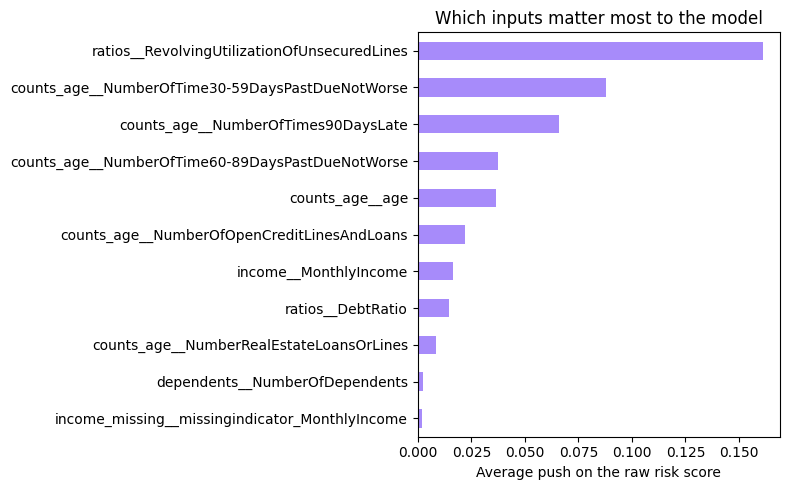


Example borrower (highest raw score in the sample):
Credit card usage (share of limit used)       1.061
Age                                          39.000
Times 30-59 days late                         2.000
Debt ratio                                    0.574
Monthly income                            6,924.000
Open loans and credit lines                   6.000
Times 90+ days late                           3.000
Real estate loans                             4.000
Times 60-89 days late                         2.000
Number of dependents                          0.000
Name: 7034, dtype: float64

Top 5 reasons (+ pushes risk up, - pushes risk down):
counts_age__NumberOfTimes90DaysLate                0.154
ratios__RevolvingUtilizationOfUnsecuredLines       0.111
counts_age__NumberOfTime60-89DaysPastDueNotWorse   0.106
counts_age__NumberOfTime30-59DaysPastDueNotWorse   0.096
counts_age__NumberRealEstateLoansOrLines           0.010
dtype: float64


In [29]:
# Cell 22: SHAP explanations on a training sample (no test data used)
!pip install shap -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# 1) Split the fitted pipeline into preprocessing and the Random Forest
rf = final_pipe.steps[-1][1]
prep = final_pipe[:-1]

# 2) Sample 2,000 training rows and apply preprocessing
sample = X_train.sample(2000, random_state=42)
Xs = prep.transform(sample)
if not isinstance(Xs, pd.DataFrame):
    Xs = pd.DataFrame(Xs, columns=prep.get_feature_names_out(), index=sample.index)

# 3) Compute SHAP values for the "default" class
explainer = shap.TreeExplainer(rf)
sv = explainer.shap_values(Xs)
if isinstance(sv, list):          # older shap versions return one array per class
    sv = sv[1]
elif sv.ndim == 3:                # newer versions return (rows, features, classes)
    sv = sv[:, :, 1]
base = np.atleast_1d(explainer.expected_value)[-1]

# 4) Sanity check: base value + contributions must equal the raw score
raw = rf.predict_proba(Xs)[:, 1]
print("Max difference (should be near 0):", np.abs(base + sv.sum(axis=1) - raw).max().round(6))

# 5) Global importance: average size of each input's push
names = [friendly_names.get(c, c) for c in Xs.columns]
importance = (pd.Series(np.abs(sv).mean(axis=0), index=names)
              .sort_values(ascending=False))
print("\nAverage importance (mean absolute SHAP):")
print(importance.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
importance.sort_values().plot(kind="barh", color="#A78BFA", ax=ax)
ax.set_title("Which inputs matter most to the model")
ax.set_xlabel("Average push on the raw risk score")
plt.tight_layout()
plt.show()

# 6) One example: the highest-risk borrower in the sample
i = int(np.argmax(raw))
contrib = pd.Series(sv[i], index=names).sort_values(key=np.abs, ascending=False)
print("\nExample borrower (highest raw score in the sample):")
print(sample.iloc[i].rename(index=lambda c: friendly_names.get(c, c)))
print("\nTop 5 reasons (+ pushes risk up, - pushes risk down):")
print(contrib.head(5).round(3))

What it tells us

We checked which inputs the model relies on most, using a random sample of 2,000 training borrowers. The check is sound: the pieces add up exactly to the model's own score.

Credit card usage is the biggest driver, by a wide margin (average push 0.161, about double the next one). Next come the three late-payment records: 30-59 days late (0.088), 90+ days late (0.066) and 60-89 days late (0.037). Together, credit usage and late payments dominate the model. Age (0.037), number of open loans (0.022), income (0.017), debt ratio (0.014) and real estate loans (0.009) matter much less. Number of dependents and the "income not reported" flag barely matter (0.002 each).

One detail may look odd: 30-59 days late ranks above 90+ days late. A likely reason is that short delays are far more common, so they move many more borrowers' scores, while 90+ day delays are rarer but very strong when they do appear. The three late-payment inputs also overlap, so their order should not be over-read.

Example (the riskiest borrower in the sample): this person uses 106% of their credit limit, was 90+ days late 3 times, and 60-89 and 30-59 days late 2 times each. The top reasons were exactly these four, all pushing the risk up. The fifth (real estate loans) is tiny.

Limits: The numbers are on the model's raw score scale, not percentages, so we use them to rank reasons only. This is a 2,000-borrower training sample. It shows what the model relies on, not what truly causes default

Step 23: Save the final model for the dashboard

We package everything the dashboard needs into one file: the fitted pipeline, the probability calibrator, the risk band edges, the review cut-off, the input column order, clean display names and the final test results. We then reload the file and confirm it gives identical scores to the notebook version. We also redraw the importance chart with readable labels for the README.

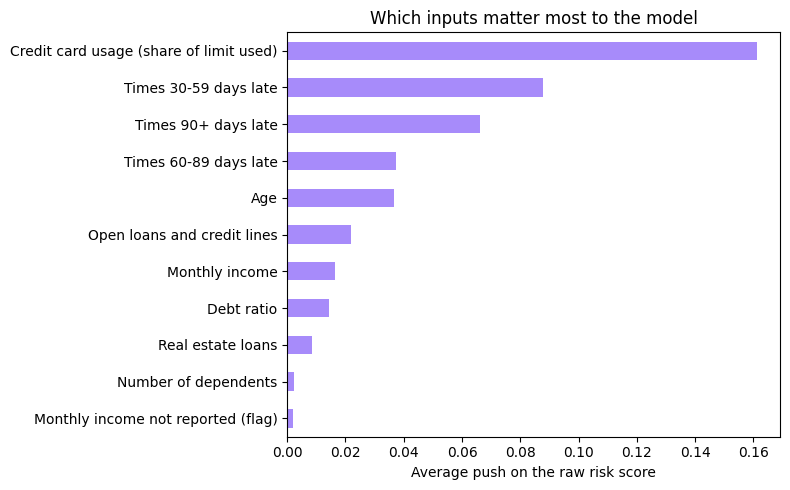

Saved: /content/drive/MyDrive/credit_risk_model/credit_risk_bundle.joblib
File size: 5.7 MB
Versions: {'python': '3.13.18', 'sklearn': '1.6.1', 'pandas': '2.2.3', 'numpy': '2.4.6'}

Max probability difference: 1.3322676295501878e-15
Same bands: True
Same flags: True


In [30]:
# Cell 23: clean labels, redraw chart, save the model bundle
import os, sys, joblib, sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SAVE_DIR = "/content/drive/MyDrive/credit_risk_model"
os.makedirs(SAVE_DIR, exist_ok=True)

# 1) Clean display names for the transformed (model) columns
def clean_name(col):
    base = col.split("__")[-1]
    if base.startswith("missingindicator_"):
        return "Monthly income not reported (flag)"
    return friendly_names.get(base, base)

shap_names = {c: clean_name(c) for c in Xs.columns}

# 2) Redraw the importance chart with readable labels and save it
imp = pd.Series(np.abs(sv).mean(axis=0),
                index=[shap_names[c] for c in Xs.columns]).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
imp.plot(kind="barh", color="#A78BFA", ax=ax)
ax.set_title("Which inputs matter most to the model")
ax.set_xlabel("Average push on the raw risk score")
plt.tight_layout()
fig.savefig(os.path.join(SAVE_DIR, "shap_importance.png"), dpi=150)
plt.show()

# 3) Build the bundle (components only, no notebook functions)
bundle = {
    "pipeline": final_pipe,
    "calibrator": calibrator,
    "band_edges": BAND_EDGES,
    "band_labels": BAND_LABELS,
    "flag_cutoff": FLAG_CUTOFF,
    "feature_order": list(X_train.columns),
    "display_names": {c: friendly_names.get(c, c) for c in X_train.columns},
    "shap_names": shap_names,
    "test_metrics": {
        "pr_auc": round(float(pr_auc), 3),
        "roc_auc": round(float(roc_auc), 3),
        "brier": round(float(brier), 4),
        "recall_at_cutoff": round(float(tp / (tp + fn)), 3),
        "precision_at_cutoff": round(float(tp / (tp + fp)), 3),
        "flagged_share": round(float((tp + fp) / (tn + fp + fn + tp)), 3),
    },
    "versions": {
        "python": sys.version.split()[0],
        "sklearn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
    },
}

path = os.path.join(SAVE_DIR, "credit_risk_bundle.joblib")
joblib.dump(bundle, path, compress=3)
print("Saved:", path)
print("File size: %.1f MB" % (os.path.getsize(path) / 1e6))
print("Versions:", bundle["versions"])

# 4) Reload check: the saved file must reproduce the notebook scores (training rows only)
loaded = joblib.load(path)

def score_from_bundle(b, X):
    X = X[b["feature_order"]]
    raw = b["pipeline"].predict_proba(X)[:, 1]
    p = np.clip(raw, 1e-6, 1 - 1e-6)
    prob = b["calibrator"].predict_proba(np.log(p / (1 - p)).reshape(-1, 1))[:, 1]
    band = pd.cut(prob, bins=b["band_edges"], labels=b["band_labels"],
                  include_lowest=True, right=False)
    return pd.DataFrame({"default_probability": prob, "risk_band": band,
                         "flag_for_review": prob >= b["flag_cutoff"]}, index=X.index)

chk_X = X_train.head(500)
a = score_borrowers(chk_X)
b = score_from_bundle(loaded, chk_X)
print("\nMax probability difference:", float(np.abs(a["default_probability"] - b["default_probability"]).max()))
print("Same bands:", bool((a["risk_band"].astype(str) == b["risk_band"].astype(str)).all()))
print("Same flags:", bool((a["flag_for_review"] == b["flag_for_review"]).all()))

What it tells us

The final model is now saved as a single file (5.7 MB) that contains everything the dashboard needs: the trained model, the probability calibrator, the risk band limits, the 15% review cut-off, the input order and the final test results.

We then reloaded the file and re-scored 500 training borrowers. The probabilities matched the notebook version to within 0.000000000000001 (a computer rounding effect, effectively zero), and all risk bands and review flags were identical. So the saved file behaves exactly like the model we tested.

We also saved a readable version of the importance chart for the README. The chart image itself was not part of this output, so this paragraph relies on the printed results only.

Limit: The saved model only works with the same library versions it was built with (scikit-learn 1.6.1 here). The dashboard must use matching versions, otherwise the file may fail to load or behave differently.

Step 24: Create the dashboard project folder

The dashboard is a separate app, not part of this notebook. In this step we create a project folder in Google Drive, copy the saved model bundle into it, and write a requirements.txt that pins the same library versions the model was built with. Pinning matters because a saved model can fail to load, or behave differently, under other versions

In [31]:
# Cell 24: create the dashboard project folder and requirements file
import os, shutil

PROJECT_DIR = "/content/drive/MyDrive/credit_risk_dashboard"
os.makedirs(os.path.join(PROJECT_DIR, "model"), exist_ok=True)

# 1) Copy the saved model bundle and the importance chart into the project
src_dir = "/content/drive/MyDrive/credit_risk_model"
for fname in ["credit_risk_bundle.joblib", "shap_importance.png"]:
    shutil.copy(os.path.join(src_dir, fname), os.path.join(PROJECT_DIR, "model", fname))

# 2) Write requirements.txt (model libraries pinned to the versions printed in Cell 23)
requirements = """streamlit
plotly
python-docx
shap
joblib
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.4.6
"""
with open(os.path.join(PROJECT_DIR, "requirements.txt"), "w") as f:
    f.write(requirements)

# 3) Show what we created
for root, _, files in os.walk(PROJECT_DIR):
    for name in files:
        p = os.path.join(root, name)
        print(p.replace(PROJECT_DIR, "credit_risk_dashboard"), "-", round(os.path.getsize(p) / 1e6, 2), "MB")

credit_risk_dashboard/requirements.txt - 0.0 MB
credit_risk_dashboard/model/credit_risk_bundle.joblib - 5.67 MB
credit_risk_dashboard/model/shap_importance.png - 0.07 MB


Step 26: Create the borrower DOCX form template

We create a fixed Word form with a table: a short field ID, a plain-language question, and an empty answer cell. Part A has the questions the model needs. Part B has three display-only questions (yearly revenue, tax paid, repayment record) that never change the probability. The credit usage ratio and the debt ratio are not asked directly; the parser will calculate them from simple amounts (credit limit, amount owed, monthly debt payments, income). We then read the file back to check it.

In [32]:
# Cell 26: create the borrower DOCX form template
!pip install python-docx -q

import os
from docx import Document
from docx.shared import Pt

PROJECT_DIR = "/content/drive/MyDrive/credit_risk_dashboard"
os.makedirs(os.path.join(PROJECT_DIR, "templates"), exist_ok=True)

part_a = [
    ("age", "Your age (years)"),
    ("monthly_income", "Monthly income before tax (PKR)"),
    ("card_limit", "Total credit limit on all credit cards and personal credit lines (PKR)"),
    ("card_balance", "Total amount you currently owe on those cards and credit lines (PKR)"),
    ("monthly_debt", "Total monthly loan and debt instalments you pay (PKR)"),
    ("late_30_59", "Times you were 30-59 days late on a payment in the last 2 years"),
    ("late_60_89", "Times you were 60-89 days late on a payment in the last 2 years"),
    ("late_90", "Times you were 90 or more days late on a payment in the last 2 years"),
    ("open_lines", "Number of open loans and credit lines (cards, car, personal, home)"),
    ("real_estate", "Number of home or real-estate loans (included in the number above)"),
    ("dependents", "Number of people who depend on your income"),
]
part_b = [
    ("yearly_revenue", "Yearly revenue (PKR)"),
    ("tax_paid", "Tax paid last year (PKR)"),
    ("repayment_record", "Repayment record (write: On time / Sometimes late / Often late)"),
]

doc = Document()
doc.styles["Normal"].font.size = Pt(10.5)
doc.add_heading("Borrower Credit History Form", level=1)
doc.add_paragraph(
    "Please write your answer in the right-hand column. Use numbers only for "
    "number questions (for example 85000, not '85,000 rupees'). Write 0 if the answer is none. "
    "Do not change the text in the first two columns."
)

def add_section(title, rows, note=None):
    doc.add_heading(title, level=2)
    if note:
        doc.add_paragraph(note)
    t = doc.add_table(rows=1, cols=3)
    t.style = "Table Grid"
    for cell, text in zip(t.rows[0].cells, ["Field ID", "Question", "Your answer"]):
        cell.text = text
        cell.paragraphs[0].runs[0].bold = True
    for fid, q in rows:
        r = t.add_row().cells
        r[0].text, r[1].text, r[2].text = fid, q, ""

add_section("Part A: used to estimate default risk", part_a)
add_section("Part B: shown on the dashboard only", part_b,
            "These answers are displayed but do not change the risk estimate.")

path = os.path.join(PROJECT_DIR, "templates", "borrower_form.docx")
doc.save(path)
print("Saved:", path)

# Read-back check
check = Document(path)
print("Tables:", len(check.tables))
for i, t in enumerate(check.tables):
    print(f"\nTable {i+1}: {len(t.rows)-1} questions")
    for row in t.rows[1:]:
        print(" ", row.cells[0].text, "|", row.cells[1].text[:60])

Saved: /content/drive/MyDrive/credit_risk_dashboard/templates/borrower_form.docx
Tables: 2

Table 1: 11 questions
  age | Your age (years)
  monthly_income | Monthly income before tax (PKR)
  card_limit | Total credit limit on all credit cards and personal credit l
  card_balance | Total amount you currently owe on those cards and credit lin
  monthly_debt | Total monthly loan and debt instalments you pay (PKR)
  late_30_59 | Times you were 30-59 days late on a payment in the last 2 ye
  late_60_89 | Times you were 60-89 days late on a payment in the last 2 ye
  late_90 | Times you were 90 or more days late on a payment in the last
  open_lines | Number of open loans and credit lines (cards, car, personal,
  real_estate | Number of home or real-estate loans (included in the number 
  dependents | Number of people who depend on your income

Table 2: 3 questions
  yearly_revenue | Yearly revenue (PKR)
  tax_paid | Tax paid last year (PKR)
  repayment_record | Repayment record (write: On 

What it tells us

The borrower form was created and saved as a Word file. We opened it again to check, and it contains two tables. Part A has 11 questions that the risk model needs. Part B has 3 questions (yearly revenue, tax paid, repayment record) that are only shown on the dashboard and never change the risk estimate.

The model needs 10 inputs, but the form asks 11 questions. This is intentional: the credit usage ratio and the debt ratio are not asked directly. They will be calculated later from the credit limit, the amount owed, the monthly instalments and the monthly income.

Limit: We only checked that the form was written correctly. We have not yet tested it with a filled-in form. The debt ratio calculated from instalments alone is an approximation of the ratio used in the training data.

Step 27: Create test forms for the parser

We create two filled-in copies of the form: one with valid answers, and one with deliberate mistakes (age under 18, a negative number, a text answer in a number field, a blank answer, and a credit limit of zero). These let us test that the parser reads good forms correctly and rejects bad ones with clear messages. All values are made up.

In [33]:
# Cell 27: create a valid and an invalid filled-in test form
import os
from docx import Document

PROJECT_DIR = "/content/drive/MyDrive/credit_risk_dashboard"
template = os.path.join(PROJECT_DIR, "templates", "borrower_form.docx")
os.makedirs(os.path.join(PROJECT_DIR, "test_forms"), exist_ok=True)

def fill_form(answers, out_name):
    doc = Document(template)
    for table in doc.tables:
        for row in table.rows[1:]:
            fid = row.cells[0].text.strip()
            if fid in answers:
                row.cells[2].text = str(answers[fid])
    out = os.path.join(PROJECT_DIR, "test_forms", out_name)
    doc.save(out)
    return out

# Made-up valid borrower
valid = {
    "age": 39, "monthly_income": 85000,
    "card_limit": 300000, "card_balance": 90000, "monthly_debt": 20000,
    "late_30_59": 1, "late_60_89": 0, "late_90": 0,
    "open_lines": 4, "real_estate": 1, "dependents": 2,
    "yearly_revenue": 1200000, "tax_paid": 96000, "repayment_record": "On time",
}

# Made-up invalid borrower (deliberate mistakes)
invalid = dict(valid)
invalid.update({
    "age": 15,                    # under 18
    "monthly_income": "abc",      # text in a number field
    "card_limit": 0,              # zero limit (cannot divide)
    "late_90": -2,                # negative count
    "dependents": "",             # blank
})

p1 = fill_form(valid, "valid_borrower.docx")
p2 = fill_form(invalid, "invalid_borrower.docx")
print("Saved:", p1)
print("Saved:", p2)

# Read back the valid form to confirm answers landed in the right rows
check = Document(p1)
for t in check.tables:
    for row in t.rows[1:]:
        print(f"{row.cells[0].text:18} -> {row.cells[2].text}")

Saved: /content/drive/MyDrive/credit_risk_dashboard/test_forms/valid_borrower.docx
Saved: /content/drive/MyDrive/credit_risk_dashboard/test_forms/invalid_borrower.docx
age                -> 39
monthly_income     -> 85000
card_limit         -> 300000
card_balance       -> 90000
monthly_debt       -> 20000
late_30_59         -> 1
late_60_89         -> 0
late_90            -> 0
open_lines         -> 4
real_estate        -> 1
dependents         -> 2
yearly_revenue     -> 1200000
tax_paid           -> 96000
repayment_record   -> On time


What it tells us

Two filled-in test forms were created from the template. We read the valid one back and all 14 answers sit next to the correct field IDs, so the template can be filled and read by field ID without mixing up rows. The second form contains deliberate mistakes; we did not print it, because the parser in the next step will be the one to check it.

Limit: All values are made up, and this only proves that the file structure works. It does not yet show that the validation rules catch bad input

Step 28: Write the form parser with validation

We write a reusable form_parser.py into the dashboard project. It reads a filled DOCX by field ID, checks every answer (number or not, whole number where needed, allowed range, blank answers, home loans not above total loans, allowed repayment-record words), and reports all problems at once. If everything is valid it also calculates the credit usage ratio and the debt ratio. No prediction is made if there is any error. We then test it on both forms and on a few edge cases.

In [34]:
# Cell 28: write form_parser.py and test it
import os, sys, importlib

PROJECT_DIR = "/content/drive/MyDrive/credit_risk_dashboard"

parser_code = r'''
import math
from docx import Document

# kind: "int" = whole number, "num" = any number
# lo/hi = allowed range; lo_strict = value must be strictly above lo
FIELDS = {
    "age":            dict(kind="int", lo=18, hi=100),
    "monthly_income": dict(kind="num", lo=0, lo_strict=True),
    "card_limit":     dict(kind="num", lo=0, lo_strict=True),
    "card_balance":   dict(kind="num", lo=0),
    "monthly_debt":   dict(kind="num", lo=0),
    "late_30_59":     dict(kind="int", lo=0, hi=98),
    "late_60_89":     dict(kind="int", lo=0, hi=98),
    "late_90":        dict(kind="int", lo=0, hi=98),
    "open_lines":     dict(kind="int", lo=0, hi=100),
    "real_estate":    dict(kind="int", lo=0, hi=100),
    "dependents":     dict(kind="int", lo=0, hi=20),
    "yearly_revenue": dict(kind="num", lo=0),
    "tax_paid":       dict(kind="num", lo=0),
}
RECORD_CHOICES = {"on time": "On time", "sometimes late": "Sometimes late", "often late": "Often late"}


def read_form(path):
    # Return {field_id: answer_text} from every table row of the form
    doc = Document(path)
    raw = {}
    for table in doc.tables:
        for row in table.rows[1:]:
            cells = row.cells
            if len(cells) >= 3:
                raw[cells[0].text.strip()] = cells[2].text.strip()
    return raw


def _to_number(text):
    t = text.replace(",", "").replace(" ", "")
    try:
        v = float(t)
    except ValueError:
        return None
    return v if math.isfinite(v) else None


def validate_form(raw):
    errors, warnings, values = [], [], {}

    for fid, rule in FIELDS.items():
        if fid not in raw:
            errors.append(f"{fid}: field is missing from the form (wrong template?)")
            continue
        text = raw[fid].strip()
        if text == "":
            errors.append(f"{fid}: answer is blank (write 0 if the answer is none)")
            continue
        v = _to_number(text)
        if v is None:
            errors.append(f"{fid}: '{text}' is not a number")
            continue
        if rule["kind"] == "int":
            if not float(v).is_integer():
                errors.append(f"{fid}: must be a whole number, got '{text}'")
                continue
            v = int(v)
        lo, hi = rule.get("lo"), rule.get("hi")
        if lo is not None:
            if rule.get("lo_strict") and v <= lo:
                errors.append(f"{fid}: must be greater than {lo}, got {text}")
                continue
            if not rule.get("lo_strict") and v < lo:
                errors.append(f"{fid}: must be at least {lo}, got {text}")
                continue
        if hi is not None and v > hi:
            errors.append(f"{fid}: must be at most {hi}, got {text}")
            continue
        values[fid] = v

    # Repayment record (display only)
    rec = raw.get("repayment_record", "").strip().lower()
    if rec == "":
        errors.append("repayment_record: answer is blank")
    elif rec not in RECORD_CHOICES:
        errors.append("repayment_record: write On time, Sometimes late or Often late")
    else:
        values["repayment_record"] = RECORD_CHOICES[rec]

    # Cross-field checks
    if "real_estate" in values and "open_lines" in values and values["real_estate"] > values["open_lines"]:
        errors.append("real_estate: cannot be more than the total number of open loans and credit lines")

    # Ratios (only when their inputs are valid)
    ratios = {}
    if "card_balance" in values and "card_limit" in values:
        ratios["credit_usage"] = values["card_balance"] / values["card_limit"]
        if ratios["credit_usage"] > 1:
            warnings.append("card_balance is above card_limit (over the limit); allowed, but check it")
    if "monthly_debt" in values and "monthly_income" in values:
        ratios["debt_ratio"] = values["monthly_debt"] / values["monthly_income"]
    if "tax_paid" in values and "yearly_revenue" in values and values["tax_paid"] > values["yearly_revenue"]:
        warnings.append("tax_paid is above yearly_revenue; check it (display only)")

    return {"ok": len(errors) == 0, "errors": errors, "warnings": warnings,
            "values": values, "ratios": ratios}


def parse_form(path):
    return validate_form(read_form(path))
'''

with open(os.path.join(PROJECT_DIR, "form_parser.py"), "w") as f:
    f.write(parser_code.lstrip("\n"))

# Load (or reload) the module from Drive
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)
import form_parser
importlib.reload(form_parser)

def show(title, result):
    print("=" * 60)
    print(title, "-> OK" if result["ok"] else f"-> REJECTED ({len(result['errors'])} problems)")
    for e in result["errors"]:
        print("  ERROR  :", e)
    for w in result["warnings"]:
        print("  WARNING:", w)
    if result["ok"]:
        print("  values :", result["values"])
        print("  ratios :", {k: round(v, 4) for k, v in result["ratios"].items()})

forms = os.path.join(PROJECT_DIR, "test_forms")
show("valid_borrower.docx", form_parser.parse_form(os.path.join(forms, "valid_borrower.docx")))
show("invalid_borrower.docx", form_parser.parse_form(os.path.join(forms, "invalid_borrower.docx")))

# Edge cases on the valid answers
base = form_parser.read_form(os.path.join(forms, "valid_borrower.docx"))
def variant(**changes):
    d = dict(base); d.update(changes); return form_parser.validate_form(d)

show("edge: income written as '85,000'", variant(monthly_income="85,000"))
show("edge: age '39.5'", variant(age="39.5"))
show("edge: real_estate 9 but open_lines 4", variant(real_estate="9"))
show("edge: balance above limit", variant(card_balance="350000"))

valid_borrower.docx -> OK
  values : {'age': 39, 'monthly_income': 85000.0, 'card_limit': 300000.0, 'card_balance': 90000.0, 'monthly_debt': 20000.0, 'late_30_59': 1, 'late_60_89': 0, 'late_90': 0, 'open_lines': 4, 'real_estate': 1, 'dependents': 2, 'yearly_revenue': 1200000.0, 'tax_paid': 96000.0, 'repayment_record': 'On time'}
  ratios : {'credit_usage': 0.3, 'debt_ratio': 0.2353}
invalid_borrower.docx -> REJECTED (5 problems)
  ERROR  : age: must be at least 18, got 15
  ERROR  : monthly_income: 'abc' is not a number
  ERROR  : card_limit: must be greater than 0, got 0
  ERROR  : late_90: must be at least 0, got -2
  ERROR  : dependents: answer is blank (write 0 if the answer is none)
edge: income written as '85,000' -> OK
  values : {'age': 39, 'monthly_income': 85000.0, 'card_limit': 300000.0, 'card_balance': 90000.0, 'monthly_debt': 20000.0, 'late_30_59': 1, 'late_60_89': 0, 'late_90': 0, 'open_lines': 4, 'real_estate': 1, 'dependents': 2, 'yearly_revenue': 1200000.0, 'tax_paid':

arkdown cell (What it tells us, paste karo):

What it tells us

The form reader works. The valid test form was accepted and the two ratios were calculated correctly: credit usage is 30% (90,000 owed on a 300,000 limit) and the debt ratio is 0.2353 (20,000 of instalments on 85,000 income).

The deliberately broken form was rejected with five clear messages, one for each planted mistake (age 15, text in the income field, zero credit limit, a negative late count and a blank answer). All problems were reported at once, so a borrower can fix the form in one go. No prediction would be made for it.

The edge cases behaved sensibly: a number written with a comma was accepted, a decimal age and a home-loan count above the total loans were rejected, and a balance above the limit was accepted with a warning instead of being blocked.

Limits: The rules only check that answers are possible, not that they are true. A wrong but plausible age (93 instead of 39) would pass. The debt ratio uses loan instalments only, while the training data's ratio also includes living costs, so it is an approximation.

Step 29: Connect the parser to the model (first real prediction)

We write a reusable scoring.py into the dashboard project. It converts monthly income from PKR to US dollars at a fixed, adjustable rate (the training data is a US-style dataset), builds the ten model inputs in the right order, and returns the calibrated default probability, risk band and review flag. We test it on the made-up valid form, check that the invalid form is refused before any prediction, and show how much the currency choice changes the result. The test set is not used.

In [35]:
# Cell 29: write scoring.py and make the first real prediction (made-up forms only)
import os, sys, importlib, joblib

PROJECT_DIR = "/content/drive/MyDrive/credit_risk_dashboard"

scoring_code = r'''
import numpy as np
import pandas as pd

# Fixed, adjustable conversion rate (placeholder; set to the rate you want to use)
PKR_PER_USD = 278.0


def build_features(values, ratios, feature_order, pkr_per_usd=PKR_PER_USD):
    # Map parser output to the ten model inputs (income converted to USD)
    row = {
        "RevolvingUtilizationOfUnsecuredLines": ratios["credit_usage"],
        "age": values["age"],
        "NumberOfTime30-59DaysPastDueNotWorse": values["late_30_59"],
        "DebtRatio": ratios["debt_ratio"],
        "MonthlyIncome": values["monthly_income"] / pkr_per_usd,
        "NumberOfOpenCreditLinesAndLoans": values["open_lines"],
        "NumberOfTimes90DaysLate": values["late_90"],
        "NumberRealEstateLoansOrLines": values["real_estate"],
        "NumberOfTime60-89DaysPastDueNotWorse": values["late_60_89"],
        "NumberOfDependents": values["dependents"],
    }
    return pd.DataFrame([row])[feature_order]


def score_values(bundle, values, ratios, pkr_per_usd=PKR_PER_USD):
    # Raw score -> sigmoid calibration -> probability -> band -> flag
    X = build_features(values, ratios, bundle["feature_order"], pkr_per_usd)
    raw = float(bundle["pipeline"].predict_proba(X)[:, 1][0])
    p = min(max(raw, 1e-6), 1 - 1e-6)
    prob = float(bundle["calibrator"].predict_proba(np.array([[np.log(p / (1 - p))]]))[:, 1][0])
    band = pd.cut([prob], bins=bundle["band_edges"], labels=bundle["band_labels"],
                  include_lowest=True, right=False)[0]
    return {
        "raw_score": raw,
        "default_probability": prob,
        "risk_band": str(band),
        "flag_for_review": bool(prob >= bundle["flag_cutoff"]),
        "income_usd_used": float(X["MonthlyIncome"].iloc[0]),
    }


def score_form(bundle, parsed, pkr_per_usd=PKR_PER_USD):
    # Refuse to predict if the form has any error
    if not parsed["ok"]:
        raise ValueError("Form has errors; no prediction made: " + "; ".join(parsed["errors"]))
    return score_values(bundle, parsed["values"], parsed["ratios"], pkr_per_usd)
'''

with open(os.path.join(PROJECT_DIR, "scoring.py"), "w") as f:
    f.write(scoring_code.lstrip("\n"))

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)
import form_parser, scoring
importlib.reload(form_parser)
importlib.reload(scoring)

bundle = joblib.load(os.path.join(PROJECT_DIR, "model", "credit_risk_bundle.joblib"))
forms = os.path.join(PROJECT_DIR, "test_forms")

# 1) Valid form
parsed = form_parser.parse_form(os.path.join(forms, "valid_borrower.docx"))
res = scoring.score_form(bundle, parsed)
print("VALID FORM (income converted at", scoring.PKR_PER_USD, "PKR per USD)")
print("  Income sent to model (USD/month): %.0f" % res["income_usd_used"])
print("  Default probability: %.1f%%" % (res["default_probability"] * 100))
print("  Risk band:", res["risk_band"], "| Flag for review:", res["flag_for_review"])

# 2) Context: how low is this income compared with the training data?
print("\nTraining data median monthly income: %.0f" % df_clean["MonthlyIncome"].median())

# 3) Comparison: what if income were NOT converted (option b)?
res_b = scoring.score_values(bundle, parsed["values"], parsed["ratios"], pkr_per_usd=1.0)
print("\nCOMPARISON (income NOT converted, 85,000 treated as dollars)")
print("  Default probability: %.1f%% | Risk band: %s" % (res_b["default_probability"] * 100, res_b["risk_band"]))

# 4) Invalid form must be refused before any prediction
parsed_bad = form_parser.parse_form(os.path.join(forms, "invalid_borrower.docx"))
try:
    scoring.score_form(bundle, parsed_bad)
    print("\nINVALID FORM: ERROR, a prediction was made")
except ValueError as e:
    print("\nINVALID FORM refused as expected:", str(e)[:120], "...")

VALID FORM (income converted at 278.0 PKR per USD)
  Income sent to model (USD/month): 306
  Default probability: 7.0%
  Risk band: Medium (5-15%) | Flag for review: False

Training data median monthly income: 5400

COMPARISON (income NOT converted, 85,000 treated as dollars)
  Default probability: 4.1% | Risk band: Low (under 5%)

INVALID FORM refused as expected: Form has errors; no prediction made: age: must be at least 18, got 15; monthly_income: 'abc' is not a number; card_limit ...
